In [3]:
import pandas as pd
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, LeaveOneOut
import warnings
import textwrap
warnings.filterwarnings('ignore', category=UserWarning)

In [4]:
DATA_PATH = 'final_feature_matrix.csv'

In [9]:
def prepare_data(df):
    """
    Prepares the dataset by:
    - Dropping non-predictive metadata (IDs)
    - Encoding categorical variables (Gender)
    - Imputing missing values with column means
    - Normalizing all features using StandardScaler
    - Separating features (X) from the target label (y)
    """
    print("Preparing data...")
    
    # Isolate target variable and drop it from features alongside the Subject ID
    y = df['Label']
    X = df.drop(columns=['Subject Number', 'Label'], errors='ignore')
        
    # One-Hot Encode categorical variables (e.g., 'Gender_M', 'Gender_F' -> 0/1)
    if 'Gender' in X.columns:
        X = pd.get_dummies(X, columns=['Gender'], drop_first=True).astype(float)
    
    
    # Normalize the entire dataset
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(
        scaler.fit_transform(X), 
        columns=X.columns, 
        index=X.index
    )
    
    print(f"Preparation complete: {len(X_scaled)} subjects processed.")
    
    return X_scaled, y

In [10]:
df = pd.read_csv(DATA_PATH)
X, Y = prepare_data(df)
X.head()

Preparing data...
Preparation complete: 70 subjects processed.


,Interviewer Total Smiles,Subject Total Smiles,Interviewer Smile Duration Mean (s),Interviewer Smile Duration Std (s),Subject Smile Duration Mean (s),Subject Smile Duration Std (s),Interviewer Smile Intensity Mean,Interviewer Smile Intensity Std,Subject Smile Intensity Mean,Subject Smile Intensity Std,Simultaneous Smiles (Intersections) Count,Average Intersection Duration (s),Total Reactions (Subject reacted to Intv),Average Delay of Reaction (s),Std Dev of Delay of Reaction (s),% of Subject's smiles that were reactions,% of Interviewer's smiles that got a reaction,Gender_M
0,0.287222,-1.001693,-0.735581,0.108996,-1.397303,-0.588142,-1.103223,-0.107457,-0.856596,-0.215171,-1.215864,1.809098,-0.161427,0.105919,0.476085,0.571486,-0.265715,0.866025
1,-0.218578,-0.293425,0.920462,1.320236,1.191432,0.655185,-0.652314,-0.504921,1.467839,2.058766,0.030524,0.665709,1.251058,-1.852198,1.108779,1.031882,2.208333,-1.154701
2,-0.092128,0.532887,-0.110872,-0.291146,-0.690992,-0.091115,0.107210,0.025031,-0.204742,0.103835,0.742745,-0.542518,-0.867669,0.993191,-1.146208,-0.689874,-0.981103,-1.154701
3,-0.345028,-0.765604,-1.005726,-0.109099,0.168970,-0.103995,-0.068349,0.912700,-0.664217,-0.153006,-0.325587,-0.220822,-0.867669,0.993191,-1.146208,-0.689874,-0.981103,-1.154701
4,-0.977278,-0.647559,0.606700,-0.076655,0.489947,0.380910,0.531323,0.959071,0.341803,0.125102,-0.503642,1.999871,-0.867669,0.993191,-1.146208,-0.689874,-0.981103,-1.154701


In [7]:
def evaluate_kfold_detailed(X, y, K_FOLDS=7, use_l1=True, C_value=1.0, max_iter=10000):
    """
    Executes K-Fold CV and plots a massive unified grid (4 columns).
    Rows 1 to K: Training CM, Testing CM, Testing Metrics, and Feature Weights.
    Final Row: Aggregated CMs (with percentages), Mean Metrics, and Mean Weights.
    """
    # 1. FIX: Dynamic Parameter Dictionary to silence Scikit-Learn 1.8+ warnings
    if C_value == 0 or C_value is None:
        # If no penalty, omit C and l1_ratio entirely
        model_params = {
            'penalty': None,
            'solver': 'saga',
            'max_iter': max_iter,
            'random_state': 42
        }
        penalty_display = "None (λ=0)"
    else:
        # If penalty, use elasticnet to support both L1 and L2
        model_params = {
            'penalty': 'elasticnet',
            'l1_ratio': 1.0 if use_l1 else 0.0,
            'C': C_value,
            'solver': 'saga',
            'max_iter': max_iter,
            'random_state': 42
        }
        penalty_display = "L1 (Sparse)" if use_l1 else "L2 (Standard)"
    
    # 2. Setup the Base Model using dictionary unpacking
    log_reg = LogisticRegression(**model_params)
    
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # 3. Initialize Accumulators
    total_train_cm = np.zeros((2, 2), dtype=int)
    total_test_cm = np.zeros((2, 2), dtype=int)
    
    metrics_history = {
        "Accuracy": [],
        "Precision": [],
        "Recall": [],
        "F1 Score": []
    }
    
    coefs_history = [] 
    
    sns.set_theme(style="whitegrid", palette="muted")
    print(f"Starting {K_FOLDS}-Fold Detailed Analysis (Penalty: {penalty_display}, C={C_value})...")
    print("-" * 70)
    

    fig, axes = plt.subplots(K_FOLDS + 1, 4, figsize=(24, 5 * (K_FOLDS + 1)))
    fig.suptitle(f'{K_FOLDS}-Fold Evaluation & Aggregated Results | C = {C_value}', 
                 fontsize=22, fontweight='bold', y=0.98)
    
    # 4. Iterate over each Fold manually
    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        row_idx = fold - 1 
        
        # Split data for this fold
        X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
        y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
        
        # Train model
        log_reg.fit(X_train_fold, y_train_fold)
        
        # Predict on Train and Test
        y_train_pred = log_reg.predict(X_train_fold)
        y_test_pred = log_reg.predict(X_test_fold)
        
        # Calculate Confusion Matrices
        train_cm = confusion_matrix(y_train_fold, y_train_pred, labels=[0, 1])
        test_cm = confusion_matrix(y_test_fold, y_test_pred, labels=[0, 1])
        
        total_train_cm += train_cm
        total_test_cm += test_cm
        
        # Calculate Testing Metrics
        acc = accuracy_score(y_test_fold, y_test_pred)
        prec = precision_score(y_test_fold, y_test_pred, zero_division=0)
        rec = recall_score(y_test_fold, y_test_pred, zero_division=0)
        f1 = f1_score(y_test_fold, y_test_pred, zero_division=0)
        
        metrics_history["Accuracy"].append(acc)
        metrics_history["Precision"].append(prec)
        metrics_history["Recall"].append(rec)
        metrics_history["F1 Score"].append(f1)
        
        test_metrics = pd.DataFrame({
            "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
            "Score": [acc, prec, rec, f1]
        })
        
        # Extract and Store Coefficients
        coefs = log_reg.coef_[0]
        coefs_history.append(coefs)
        
        coefs_df = pd.DataFrame({
            'Feature': X.columns,
            'Coefficient': coefs
        }).sort_values(by='Coefficient', ascending=False)
        
        sns.heatmap(train_cm, annot=True, fmt='d', cmap='Greens', ax=axes[row_idx, 0],
                    annot_kws={"size": 14, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[row_idx, 0].set_title(f'Fold {fold}: Training CM', fontsize=14, fontweight='bold')
        axes[row_idx, 0].set_xlabel('Predicted', fontsize=12)
        axes[row_idx, 0].set_ylabel('Actual', fontsize=12)

        sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', ax=axes[row_idx, 1],
                    annot_kws={"size": 14, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[row_idx, 1].set_title(f'Fold {fold}: Testing CM', fontsize=14, fontweight='bold')
        axes[row_idx, 1].set_xlabel('Predicted', fontsize=12)
        axes[row_idx, 1].set_ylabel('Actual', fontsize=12)
        

        sns.barplot(x='Score', y='Metric', data=test_metrics, ax=axes[row_idx, 2], hue='Metric', palette='magma', legend=False)
        axes[row_idx, 2].set_title(f'Fold {fold}: Testing Metrics', fontsize=14, fontweight='bold')
        axes[row_idx, 2].set_xlim(0, 1.1)
        axes[row_idx, 2].set_ylabel('')
        for i in axes[row_idx, 2].containers:
            axes[row_idx, 2].bar_label(i, fmt='%.3f', padding=5, size=11, weight='bold')
            

        sns.barplot(x='Coefficient', y='Feature', data=coefs_df, ax=axes[row_idx, 3], hue='Feature', palette='mako', legend=False)
        axes[row_idx, 3].set_title(f'Fold {fold}: Feature Weights', fontsize=14, fontweight='bold')
        axes[row_idx, 3].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
        axes[row_idx, 3].set_ylabel('')



    print(f"Completed {K_FOLDS} Folds. Rendering Aggregate Matrix...")
    last_row = K_FOLDS
    
    # Helper function to create text annotations combining Counts + Percentages
    def get_percentage_annotations(cm):
        total = np.sum(cm)
        annot = np.empty_like(cm, dtype=object)
        for i in range(2):
            for j in range(2):
                count = cm[i, j]
                pct = (count / total) * 100 if total > 0 else 0
                annot[i, j] = f"{count}\n({pct:.1f}%)"
        return annot

    train_annot = get_percentage_annotations(total_train_cm)
    test_annot = get_percentage_annotations(total_test_cm)
    

    sns.heatmap(total_train_cm, annot=train_annot, fmt='', cmap='Greens', ax=axes[last_row, 0],
                annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    axes[last_row, 0].set_title('GRAND TOTAL: Training Folds', fontsize=16, fontweight='bold', color='darkgreen')
    axes[last_row, 0].set_xlabel('Predicted', fontsize=13)
    axes[last_row, 0].set_ylabel('Actual', fontsize=13)
    

    sns.heatmap(total_test_cm, annot=test_annot, fmt='', cmap='Blues', ax=axes[last_row, 1],
                annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    axes[last_row, 1].set_title('GRAND TOTAL: Testing Folds', fontsize=16, fontweight='bold', color='darkblue')
    axes[last_row, 1].set_xlabel('Predicted', fontsize=13)
    axes[last_row, 1].set_ylabel('Actual', fontsize=13)
    

    mean_metrics = pd.DataFrame({
        "Metric": ["Mean Accuracy", "Mean Precision", "Mean Recall", "Mean F1 Score"],
        "Score": [
            np.mean(metrics_history["Accuracy"]),
            np.mean(metrics_history["Precision"]),
            np.mean(metrics_history["Recall"]),
            np.mean(metrics_history["F1 Score"])
        ]
    })
    
    sns.barplot(x='Score', y='Metric', data=mean_metrics, ax=axes[last_row, 2], hue='Metric', palette='flare', legend=False)
    axes[last_row, 2].set_title('GRAND TOTAL: Mean Testing Metrics', fontsize=16, fontweight='bold', color='darkred')
    axes[last_row, 2].set_xlim(0, 1.1)
    axes[last_row, 2].set_ylabel('')
    for i in axes[last_row, 2].containers:
        axes[last_row, 2].bar_label(i, fmt='%.3f', padding=5, size=13, weight='bold')


    mean_coefs = np.mean(coefs_history, axis=0)
    mean_coefs_df = pd.DataFrame({
        'Feature': X.columns,
        'Mean Coefficient': mean_coefs
    }).sort_values(by='Mean Coefficient', ascending=False)
    
    sns.barplot(x='Mean Coefficient', y='Feature', data=mean_coefs_df, ax=axes[last_row, 3], hue='Feature', palette='mako', legend=False)
    axes[last_row, 3].set_title('GRAND TOTAL: Mean Feature Weights', fontsize=16, fontweight='bold', color='darkblue')
    axes[last_row, 3].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
    axes[last_row, 3].set_ylabel('')

    # Final visual cleanup
    sns.despine()
    plt.tight_layout()
    fig.subplots_adjust(top=0.96) # Prevent title overlap
    plt.show()

Preparing data...
Preparation complete: 70 subjects processed.
Starting 7-Fold Detailed Analysis (Penalty: L2 (Standard), C=1)...
----------------------------------------------------------------------


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

Completed 7 Folds. Rendering Aggregate Matrix...


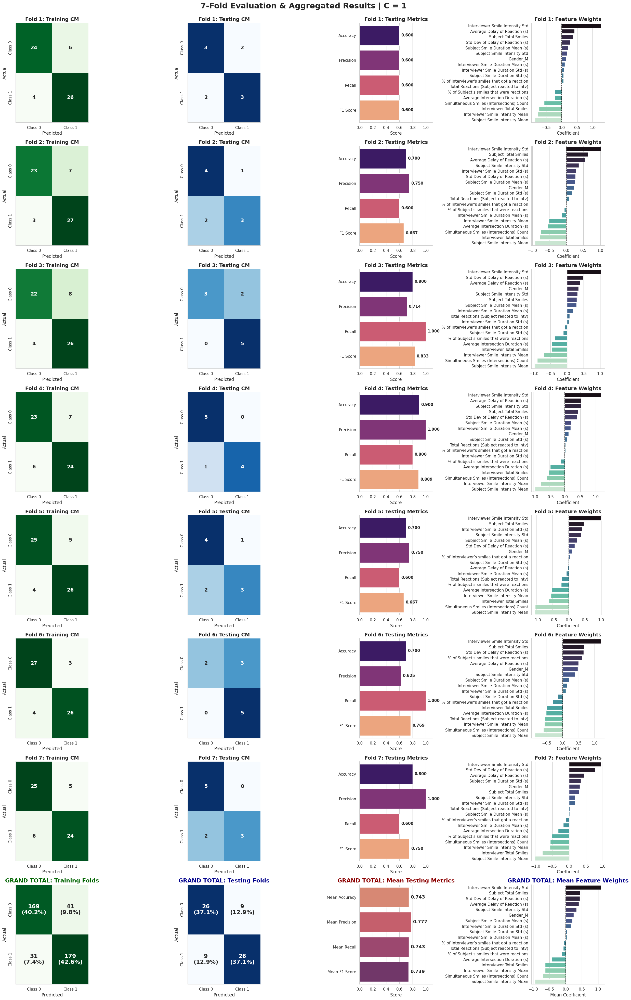

In [11]:
# Example usage:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH):
        # Using your newly updated prepare_data that normalizes and returns X, y directly
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        
        # Run the detailed 7-Fold Analysis
        evaluate_kfold_detailed(
            X=X_scaled, 
            y=y, 
            K_FOLDS=7, 
            use_l1=False, 
            C_value=1
        )

# Method1

In [12]:
def execute_pruning_for_fold(X_tr, X_te, y_tr, y_te, fold_idx, model_params, phase_name):
    """
    Helper function to recursively prune features for a single data fold.
    Tracks the 'Survival Score' (elimination order) for every feature.
    Generates a 1x4 subplot for every step until 1 feature remains.
    Returns a dictionary of {Feature_Name: Survival_Score}.
    """
    current_X_tr = X_tr.copy()
    current_X_te = X_te.copy()
    
    log_reg = LogisticRegression(**model_params)
    
    # --- NEW: Track survival scores ---
    survival_scores = {}
    current_rank = 1 
    
    print(f"\n{'='*60}")
    print(f"[{phase_name}] STARTING FOLD {fold_idx} PRUNING")
    print(f"{'='*60}")
    
    while current_X_tr.shape[1] > 0:
        num_feats = current_X_tr.shape[1]
        
        # 1. Train Model & Predict
        log_reg.fit(current_X_tr, y_tr)
        y_tr_pred = log_reg.predict(current_X_tr)
        y_te_pred = log_reg.predict(current_X_te)
        
        # 2. Calculate Matrices & Metrics
        train_cm = confusion_matrix(y_tr, y_tr_pred, labels=[0, 1])
        test_cm = confusion_matrix(y_te, y_te_pred, labels=[0, 1])
        
        acc = accuracy_score(y_te, y_te_pred)
        prec = precision_score(y_te, y_te_pred, zero_division=0)
        rec = recall_score(y_te, y_te_pred, zero_division=0)
        f1 = f1_score(y_te, y_te_pred, zero_division=0)
        
        test_metrics = pd.DataFrame({
            "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
            "Score": [acc, prec, rec, f1]
        })
        
        # 3. Extract Coefficients and identify the weakest link
        coefs = log_reg.coef_[0]
        abs_coefs = np.abs(coefs)
        min_idx = np.argmin(abs_coefs)
        feature_to_drop = current_X_tr.columns[min_idx]
        
        # --- NEW: Assign the survival score (rank) and increment ---
        survival_scores[feature_to_drop] = current_rank
        current_rank += 1
        
        # Determine plot titles and colors
        if num_feats > 1:
            drop_title = f"Dropping: [{feature_to_drop}]"
            custom_palette = {feat: '#e74c3c' if feat == feature_to_drop else '#3498db' for feat in current_X_tr.columns}
        else:
            drop_title = f"SURVIVOR: [{feature_to_drop}]"
            custom_palette = {feature_to_drop: '#2ecc71'} # Green for the final survivor
            
        iter_df = pd.DataFrame({
            'Feature': current_X_tr.columns,
            'Coefficient': coefs,
            'Abs_Coef': abs_coefs
        }).sort_values(by='Abs_Coef', ascending=False)
        
        # ---------------------------------------------------------------------
        # --- PLOT 1x4 GRID ---
        # ---------------------------------------------------------------------
        plot_height = max(4.0, num_feats * 0.4)
        fig, axes = plt.subplots(1, 4, figsize=(24, plot_height))
        fig.suptitle(f'[{phase_name}] Fold {fold_idx} | Features: {num_feats} | {drop_title}', 
                     fontsize=16, fontweight='bold', y=1.05)
        
        # Plot 1: Train CM
        sns.heatmap(train_cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
                    annot_kws={"size": 14, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[0].set_title('Training CM', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Predicted', fontsize=12)
        axes[0].set_ylabel('Actual', fontsize=12)
        
        # Plot 2: Test CM
        sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
                    annot_kws={"size": 14, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[1].set_title('Testing CM', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Predicted', fontsize=12)
        axes[1].set_ylabel('Actual', fontsize=12)
        
        # Plot 3: Test Metrics
        sns.barplot(x='Score', y='Metric', data=test_metrics, ax=axes[2], hue='Metric', palette='magma', legend=False)
        axes[2].set_title('Testing Metrics', fontsize=14, fontweight='bold')
        axes[2].set_xlim(0, 1.1)
        axes[2].set_ylabel('')
        for i in axes[2].containers:
            axes[2].bar_label(i, fmt='%.3f', padding=5, size=11, weight='bold')
            
        # Plot 4: Feature Weights
        sns.barplot(x='Coefficient', y='Feature', data=iter_df, ax=axes[3], hue='Feature', palette=custom_palette, legend=False)
        axes[3].set_title('Feature Weights (Red = Weakest)', fontsize=14, fontweight='bold')
        axes[3].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
        axes[3].set_ylabel('')
        
        sns.despine()
        plt.tight_layout()
        plt.show()
        plt.close(fig) # Prevent RAM overload
        
        # 4. Check if it's the last feature
        if num_feats == 1:
            return survival_scores # Return the full dictionary of scores, not just the single survivor
            
        # 5. Drop the feature for the next round
        current_X_tr = current_X_tr.drop(columns=[feature_to_drop])
        current_X_te = current_X_te.drop(columns=[feature_to_drop])


def evaluate_nested_pruning(X, y, K_FOLDS=7, use_l1=False, C_value=1.0, max_iter=10000):
    """
    Runs K-Fold Recursive Pruning on the full dataset, calculates Mean Survival Scores,
    and runs a final K-Fold Pruning on the subset of top survivors.
    """
    sns.set_theme(style="whitegrid", palette="muted")
    
    if C_value == 0 or C_value is None:
        model_params = {'penalty': None, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}
    else:
        model_params = {'penalty': 'elasticnet', 'l1_ratio': 1.0 if use_l1 else 0.0, 'C': C_value, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}

    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # =========================================================================
    # PHASE 1: Pruning per Fold (Full Features)
    # =========================================================================
    phase1_all_scores = {}
    phase1_top_survivors = {} # Tracks the absolute #1 feature per fold for Phase 3
    
    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        
        # Run pruning loop and get the dictionary of survival scores
        scores = execute_pruning_for_fold(X_tr, X_te, y_tr, y_te, fold, model_params, "PHASE 1 (ALL FEATURES)")
        phase1_all_scores[f"Fold {fold}"] = scores
        
        # Identify the ultimate survivor (the feature with the maximum score)
        top_feature = max(scores, key=scores.get)
        phase1_top_survivors[f"Fold {fold}"] = top_feature

    # =========================================================================
    # PHASE 2: Survival Score Analysis Dashboard
    # =========================================================================
    # Convert all scores into a clean DataFrame
    scores_df = pd.DataFrame(phase1_all_scores)
    
    # Calculate the new metric: Average Survival Score
    scores_df['Mean_Survival_Score'] = scores_df.mean(axis=1)
    scores_df = scores_df.sort_values(by='Mean_Survival_Score', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    fig.suptitle('PHASE 2: Feature Survival Score Analysis', fontsize=20, fontweight='bold', y=1.02)
    
    # Plot A: The Heatmap (Shows exact rank in every fold)
    sns.heatmap(scores_df.drop(columns=['Mean_Survival_Score']), annot=True, fmt=".0f", cmap='viridis', 
                ax=axes[0], linewidths=0.5, cbar_kws={'label': 'Survival Rank (Higher is Better)'})
    axes[0].set_title('Survival Rank per Fold', fontsize=16, fontweight='bold')
    axes[0].set_ylabel('Features', fontsize=14)
    axes[0].set_xlabel('K-Folds', fontsize=14)
    
    # Plot B: The Leaderboard (Mean Score)
    sns.barplot(x='Mean_Survival_Score', y=scores_df.index, data=scores_df, palette='magma', ax=axes[1])
    axes[1].set_title('Overall Leaderboard: Mean Survival Score', fontsize=16, fontweight='bold')
    axes[1].set_xlabel('Average Rank Across All Folds', fontsize=14)
    axes[1].set_ylabel('')
    
    # Add values to the bars
    for i in axes[1].containers:
        axes[1].bar_label(i, fmt='%.2f', padding=5, size=11, weight='bold')

    sns.despine()
    plt.tight_layout()
    plt.show()
    
    # =========================================================================
    # PHASE 3: Pruning the Top Survivors
    # =========================================================================
    # Take only the features that placed #1 in at least one fold
    unique_survivors = list(set(phase1_top_survivors.values()))
    
    print(f"\n{'#'*60}")
    print(f"PHASE 3: FINAL SHOWDOWN")
    print(f"Features that survived to the end of at least 1 fold: {unique_survivors}")
    print(f"Applying pruning process exclusively on these {len(unique_survivors)} features...")
    print(f"{'#'*60}\n")
    
    if len(unique_survivors) == 1:
        print("Only 1 feature survived across all folds! No further pruning needed.")
        print(f"ULTIMATE SURVIVOR: {unique_survivors[0]}")
        return
        
    # Isolate the dataset to ONLY the absolute winning features
    X_subset = X[unique_survivors]
    phase3_all_scores = {}
    
    for fold, (train_index, test_index) in enumerate(skf.split(X_subset, y), start=1):
        X_tr_sub, X_te_sub = X_subset.iloc[train_index], X_subset.iloc[test_index]
        y_tr_sub, y_te_sub = y.iloc[train_index], y.iloc[test_index]
        
        scores = execute_pruning_for_fold(X_tr_sub, X_te_sub, y_tr_sub, y_te_sub, fold, model_params, "PHASE 3 (SUBSET)")
        phase3_all_scores[f"Fold {fold}"] = scores
        
    # --- PHASE 3 FINAL RESULTS PLOT ---
    phase3_scores_df = pd.DataFrame(phase3_all_scores)
    phase3_scores_df['Mean_Survival_Score'] = phase3_scores_df.mean(axis=1)
    phase3_scores_df = phase3_scores_df.sort_values(by='Mean_Survival_Score', ascending=False)

    plt.figure(figsize=(10, max(4, len(unique_survivors) * 0.8)))
    sns.barplot(x='Mean_Survival_Score', y=phase3_scores_df.index, data=phase3_scores_df, palette='viridis')
    plt.title('PHASE 3 RESULTS: Ultimate Feature Resiliency', fontsize=16, fontweight='bold')
    plt.xlabel('Mean Survival Score (Subset)', fontsize=14)
    plt.ylabel('Elite Features', fontsize=14)
    
    for i in plt.gca().containers:
        plt.gca().bar_label(i, fmt='%.2f', padding=5, size=12, weight='bold')
        
    sns.despine()
    plt.tight_layout()
    plt.show()

Preparing data...
Preparation complete: 70 subjects processed.

[PHASE 1 (ALL FEATURES)] STARTING FOLD 1 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


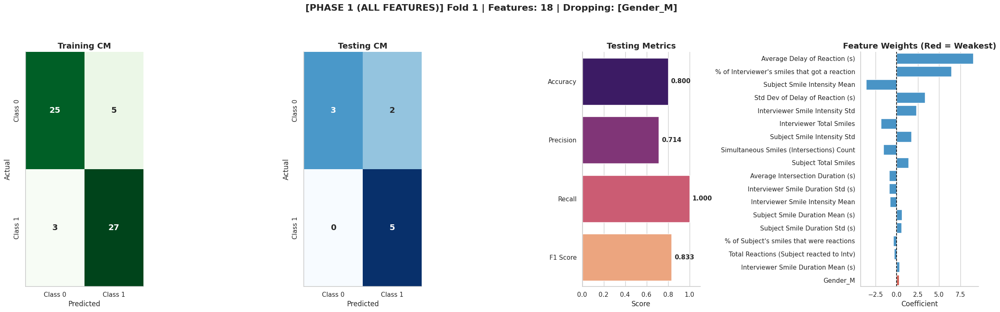

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


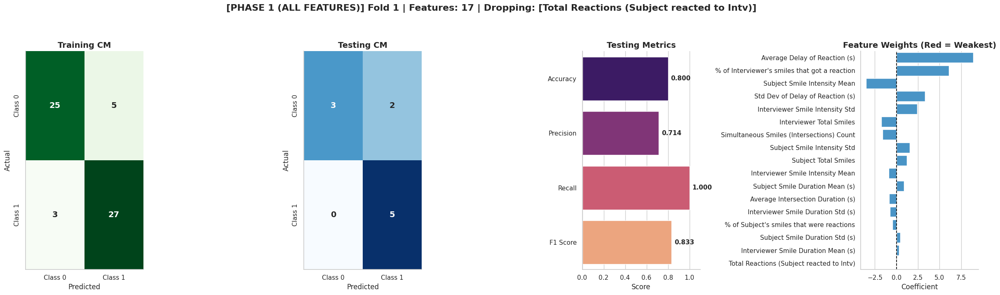

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


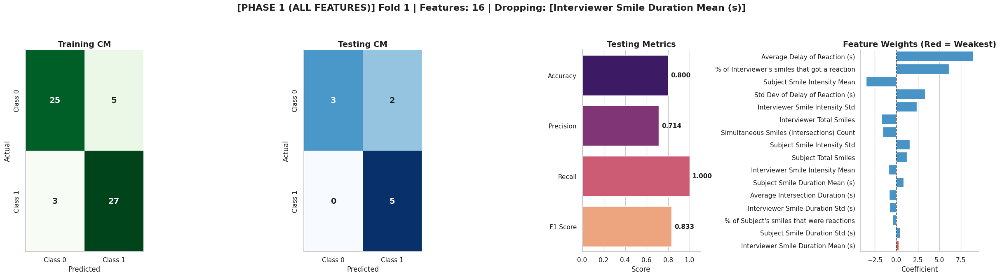

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


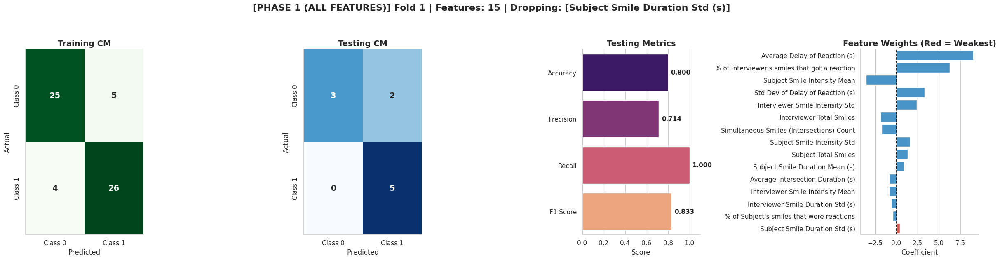

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


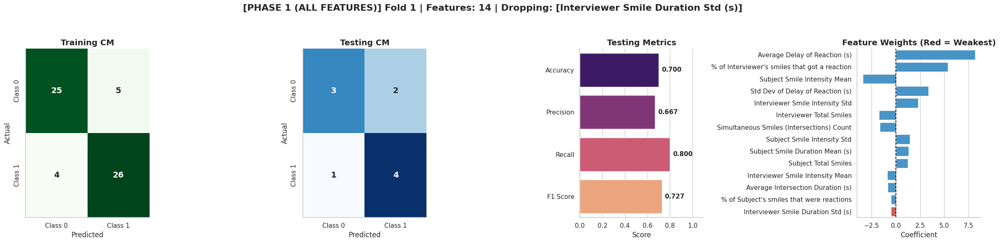

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


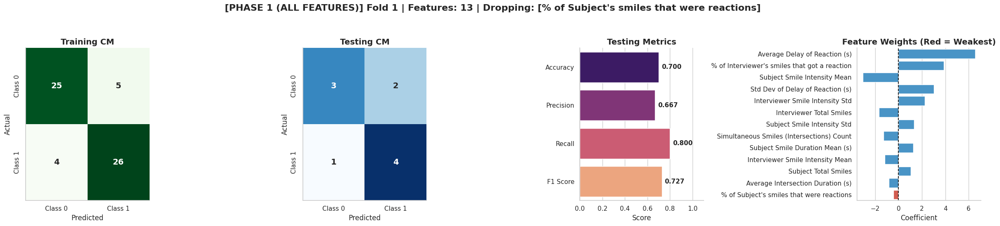

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


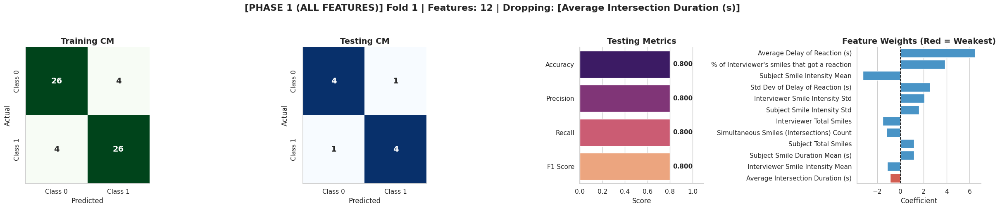

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


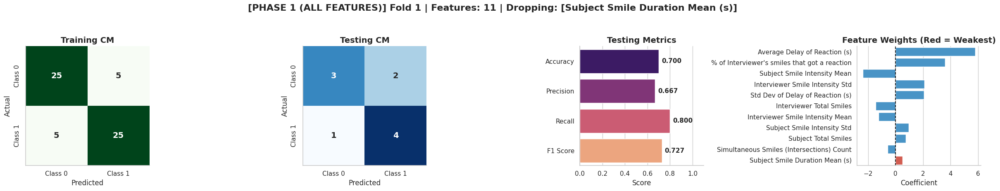

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


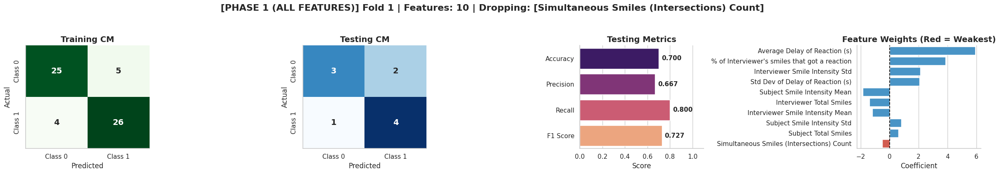

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


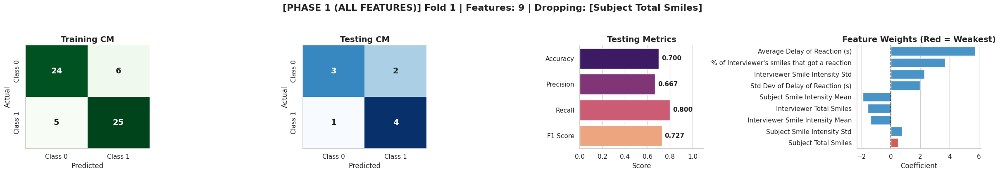

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


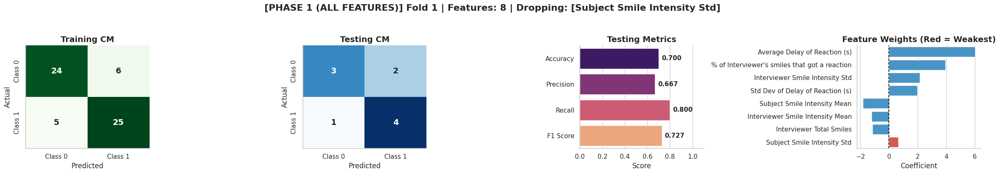

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


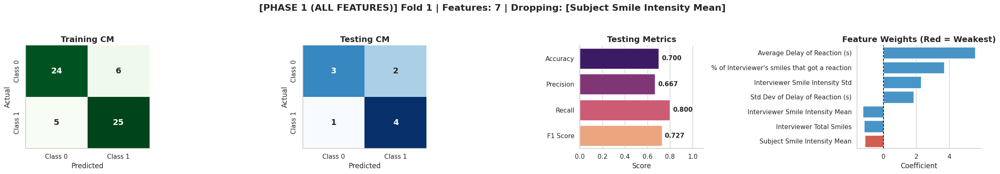

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


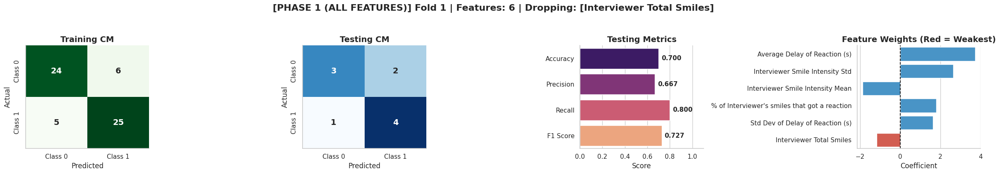

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


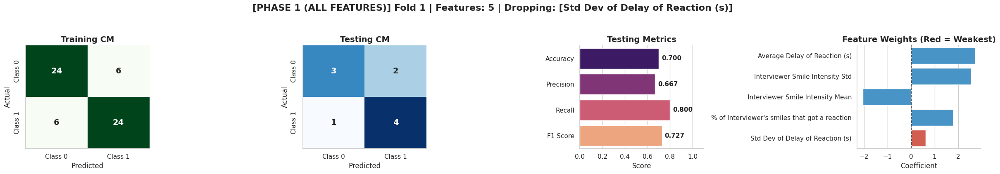

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


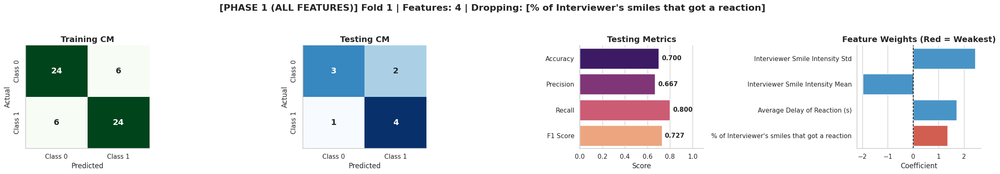

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


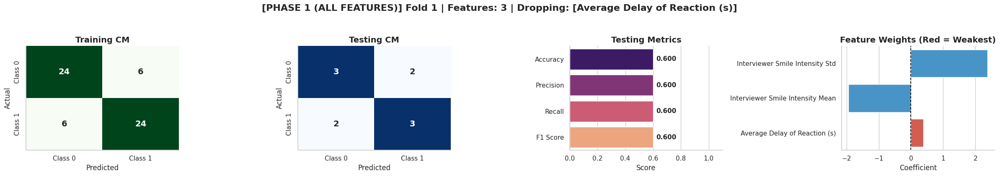

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


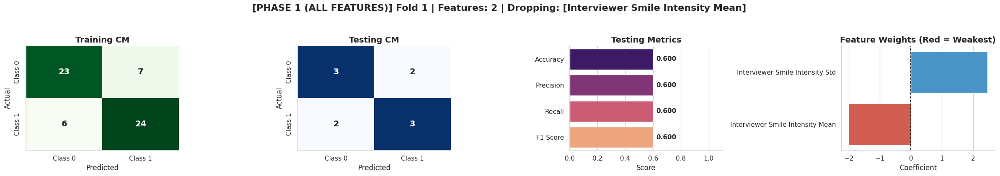

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


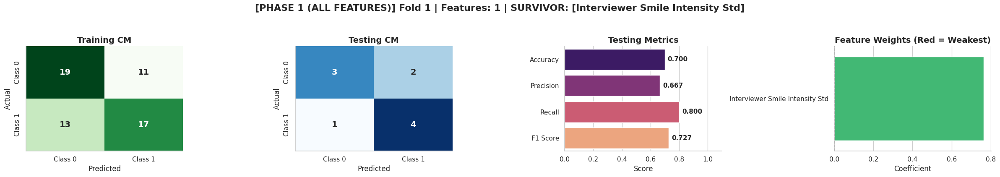


[PHASE 1 (ALL FEATURES)] STARTING FOLD 2 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


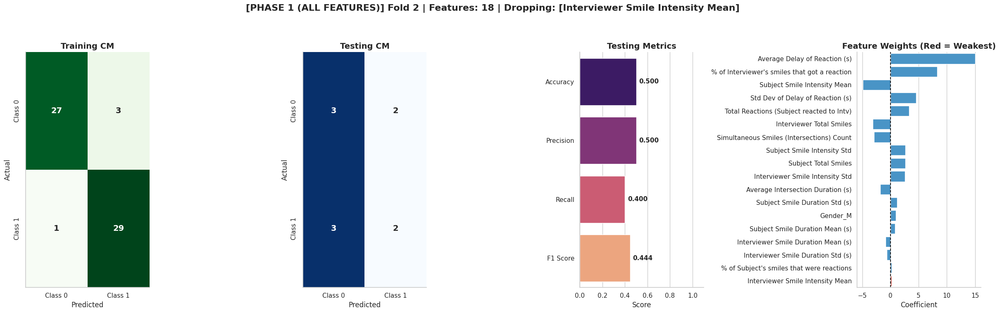

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


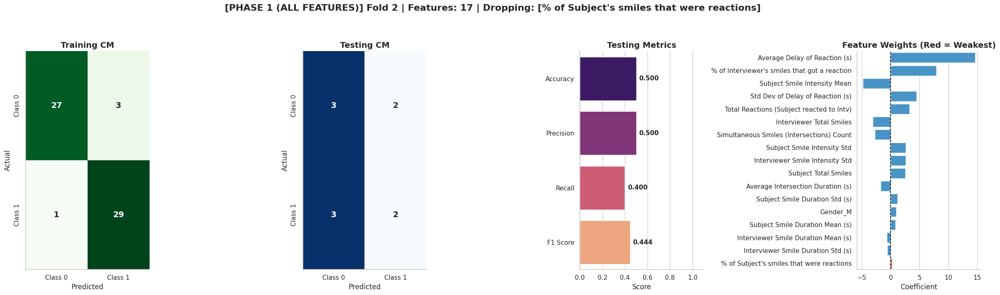

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


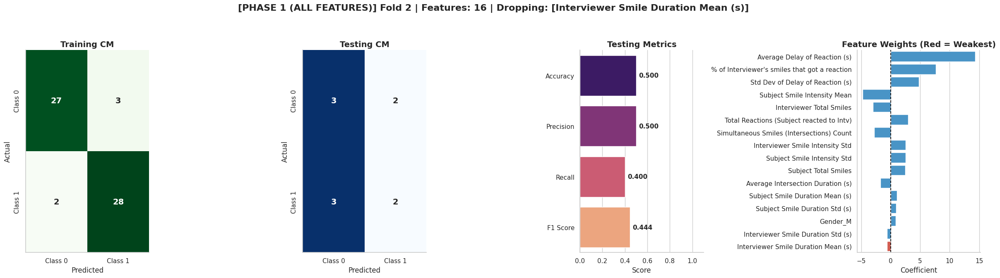

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


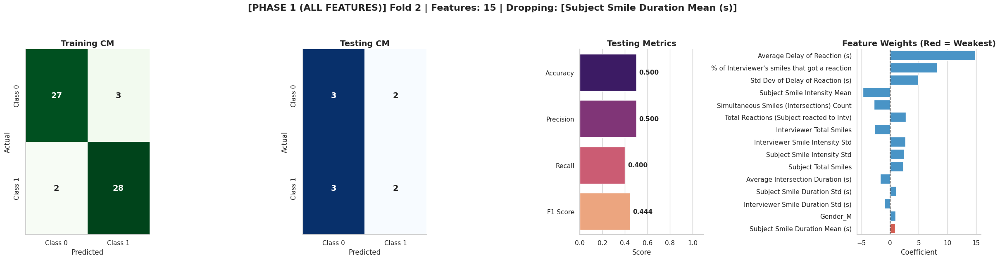

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


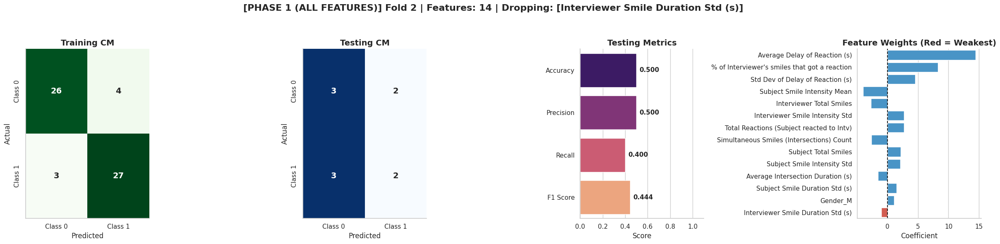

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


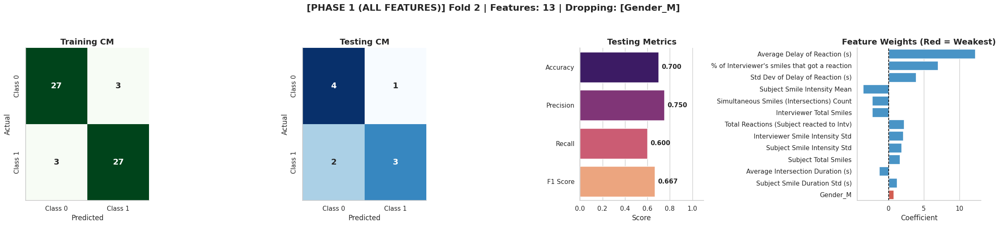

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


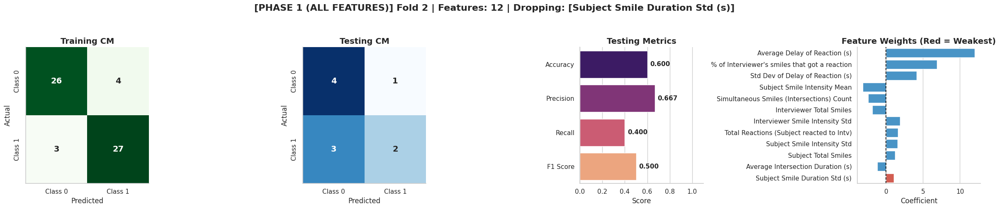

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


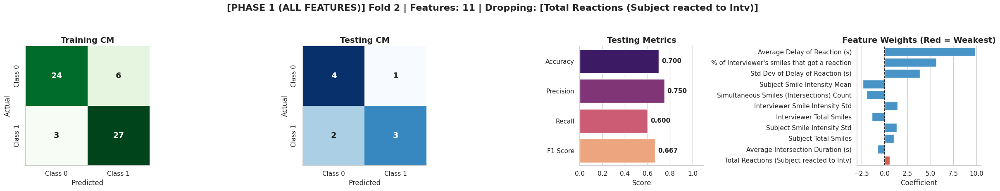

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


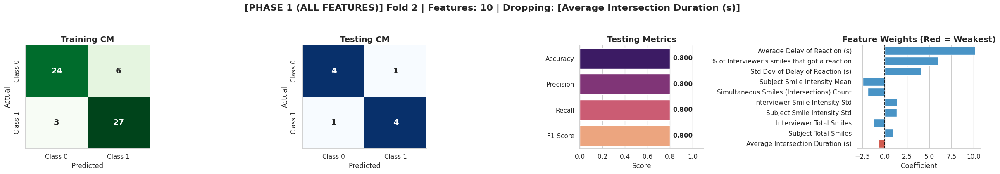

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


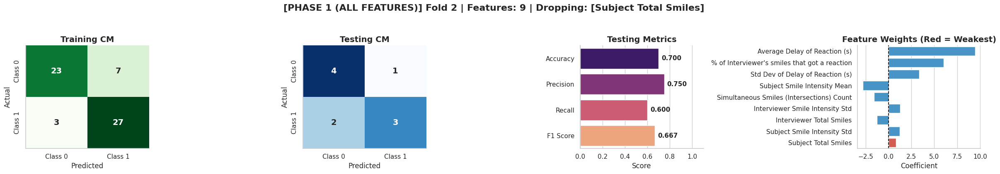

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


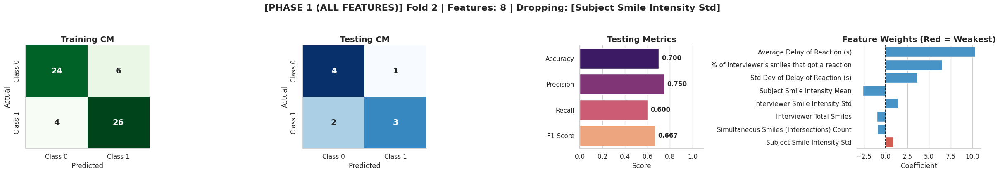

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


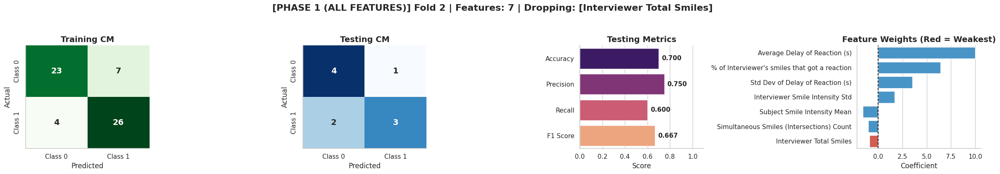

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


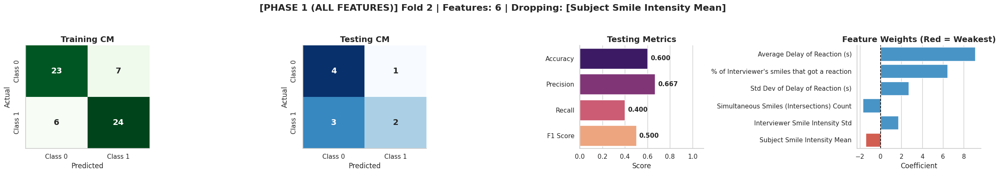

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


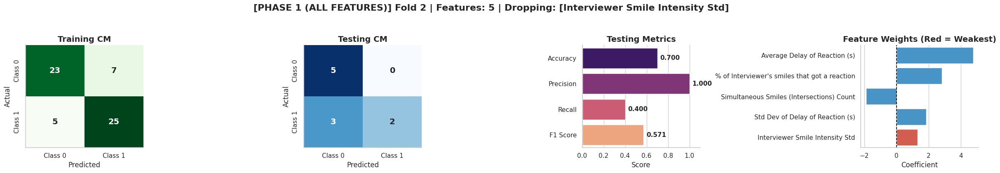

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


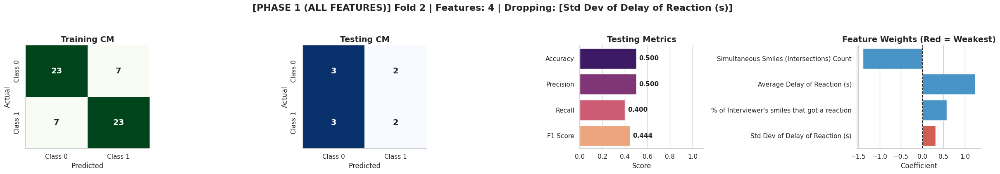

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


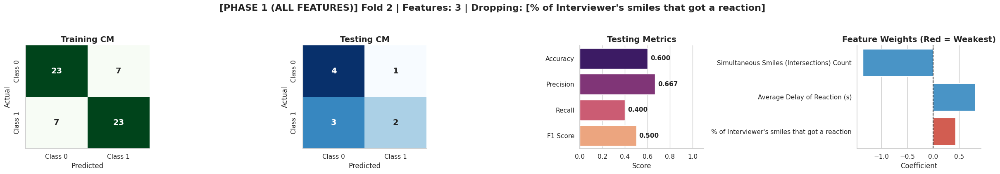

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


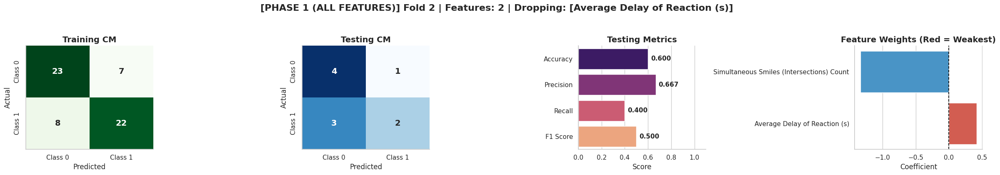

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


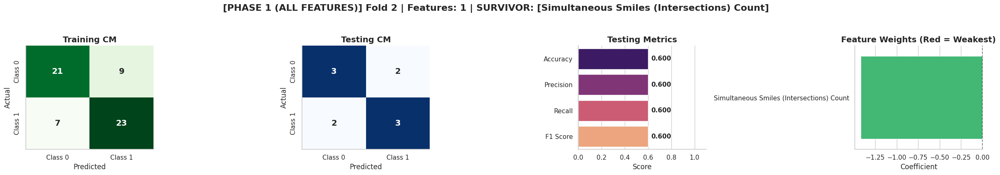


[PHASE 1 (ALL FEATURES)] STARTING FOLD 3 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


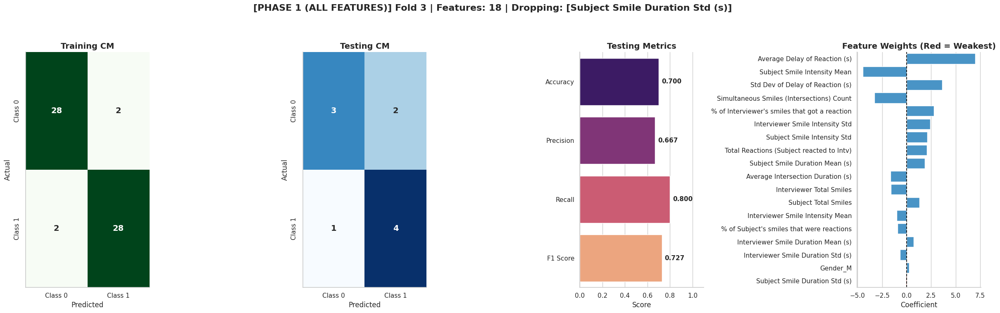

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


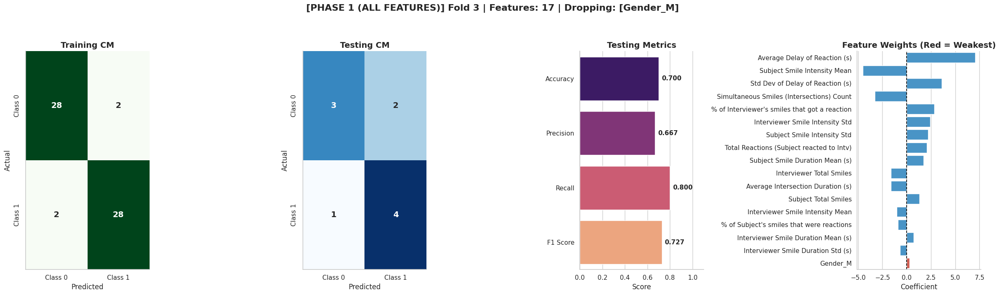

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


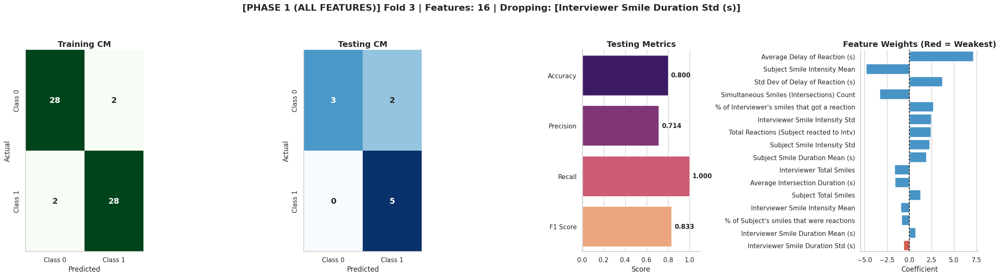

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


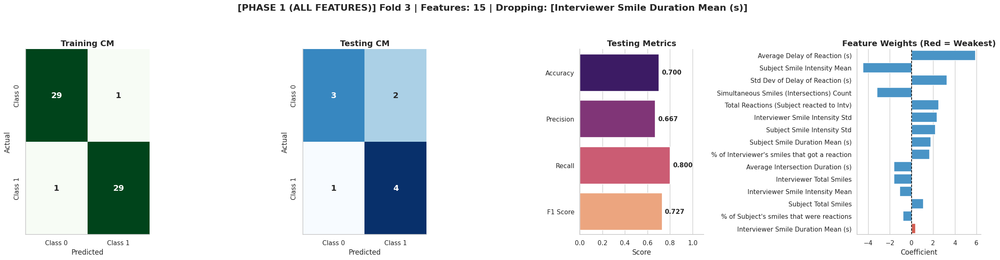

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


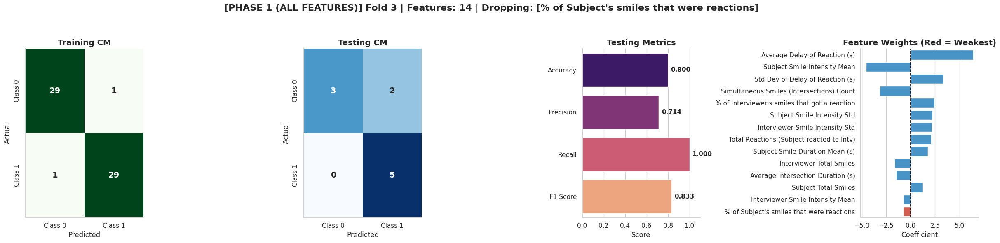

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


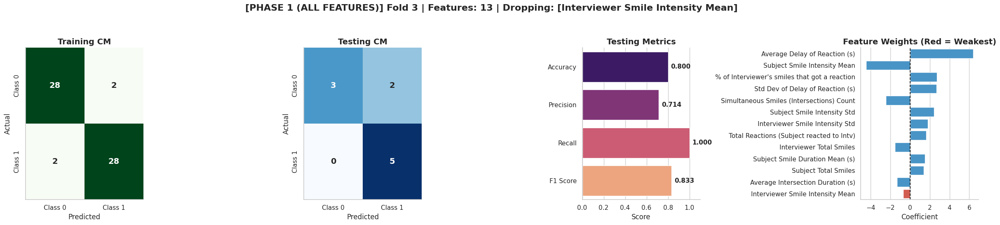

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


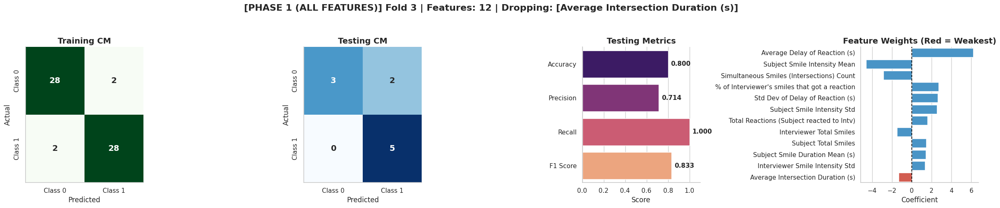

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


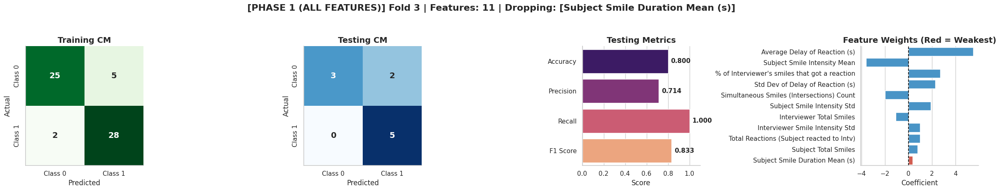

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


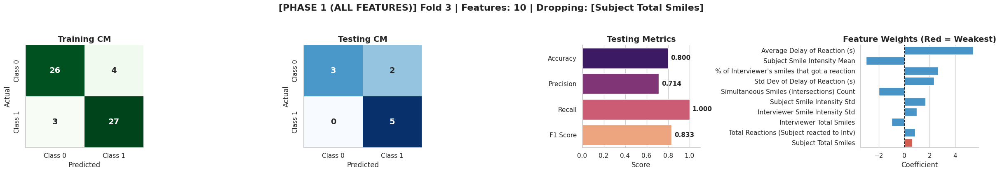

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


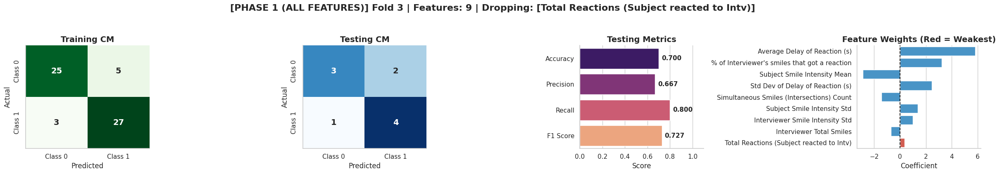

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


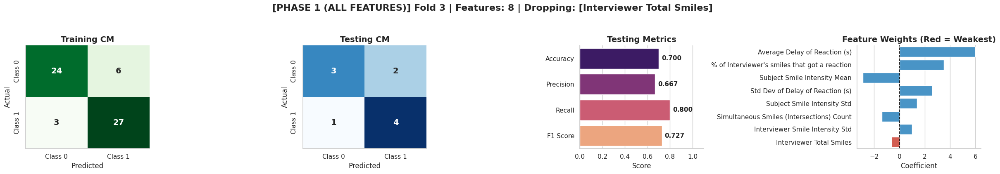

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


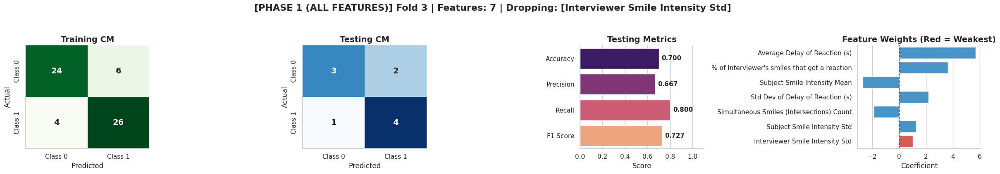

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


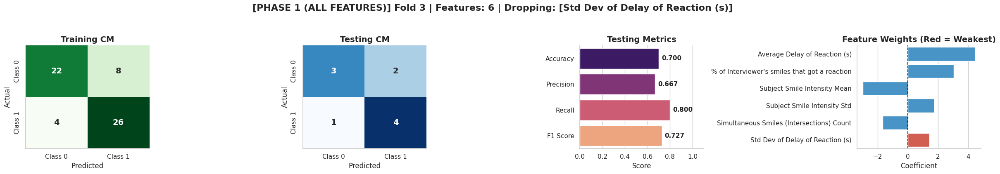

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


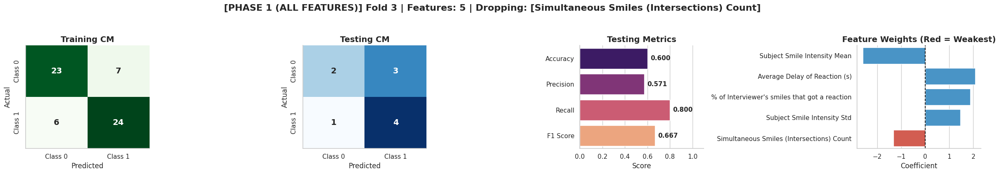

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


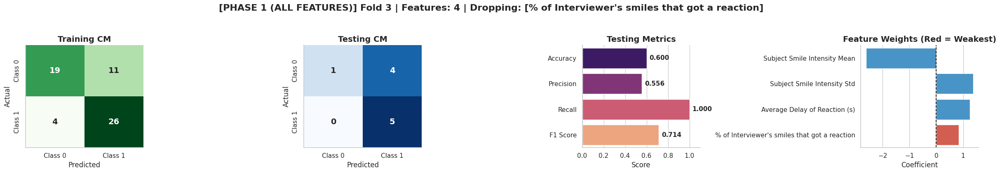

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


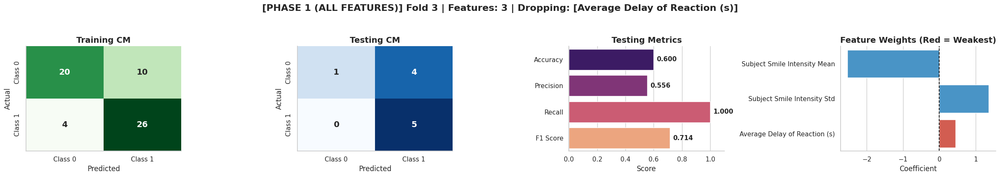

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


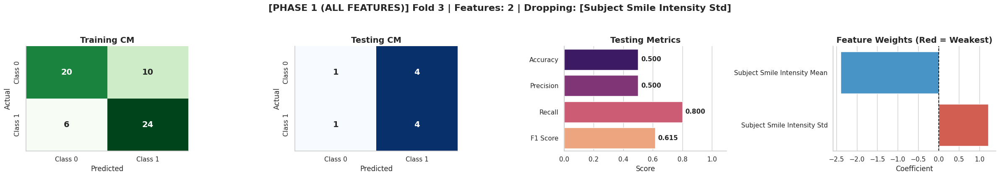

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


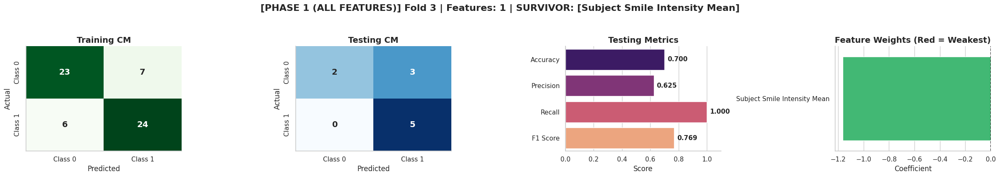


[PHASE 1 (ALL FEATURES)] STARTING FOLD 4 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


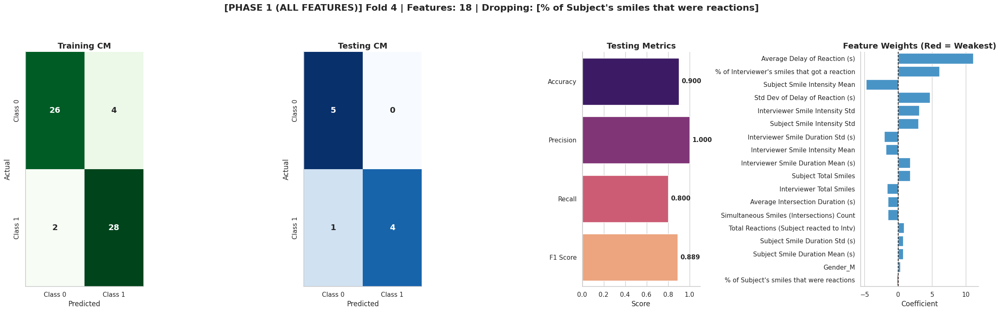

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


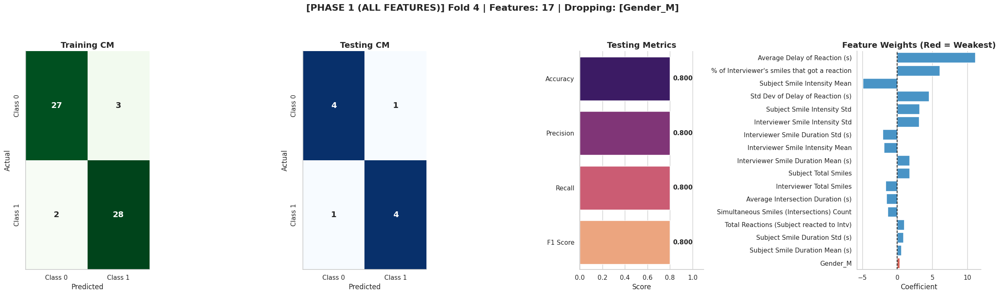

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


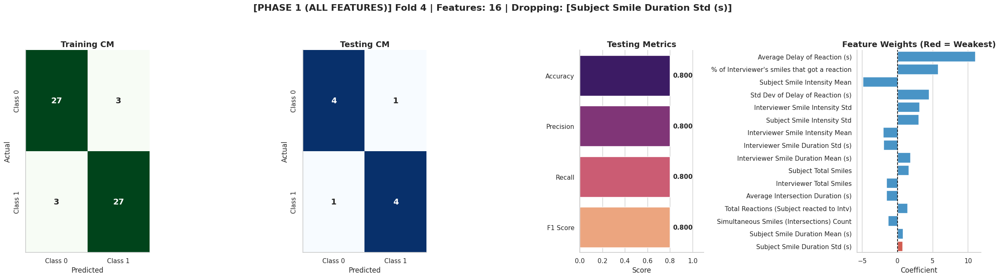

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


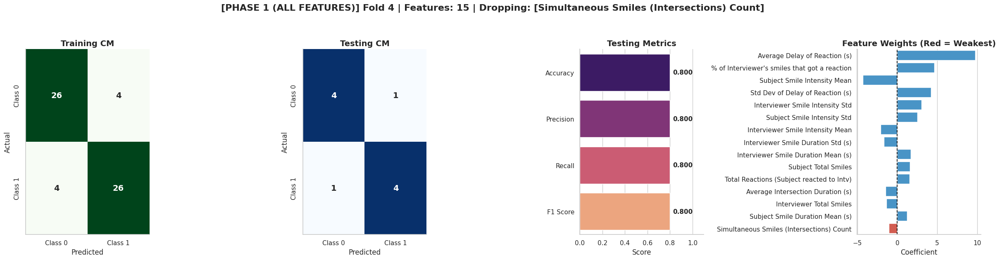

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


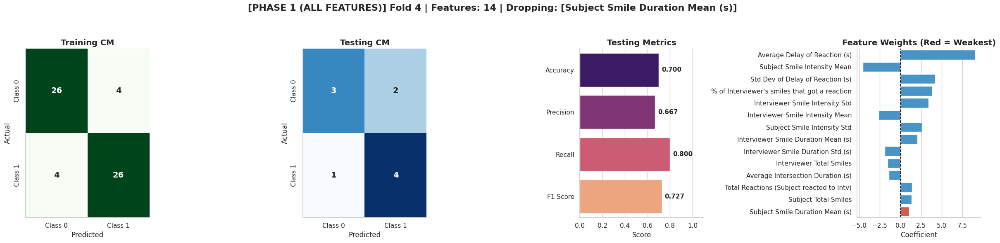

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


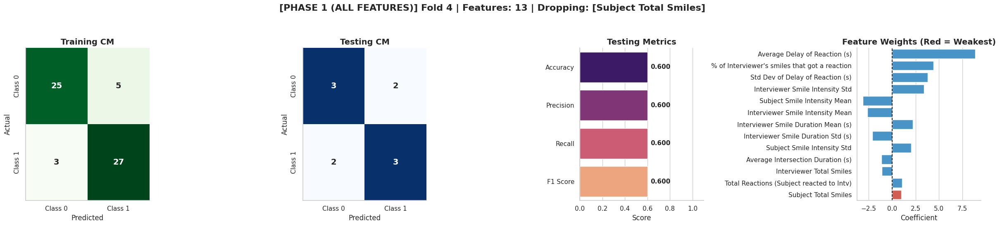

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


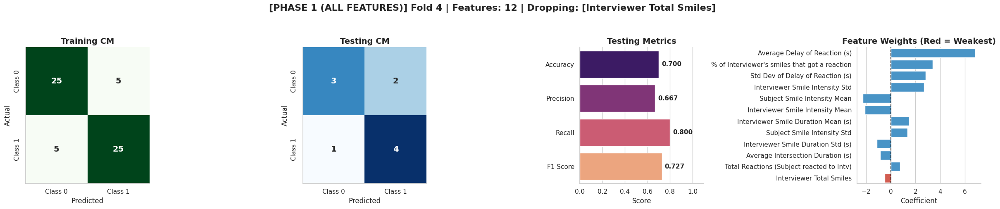

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


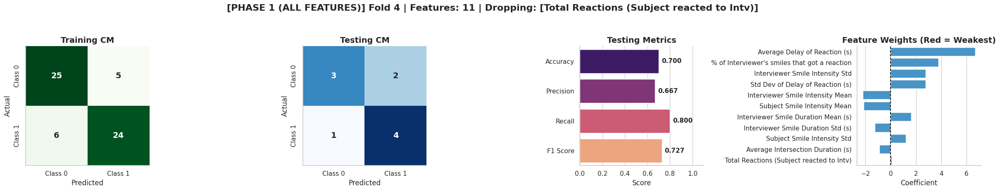

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


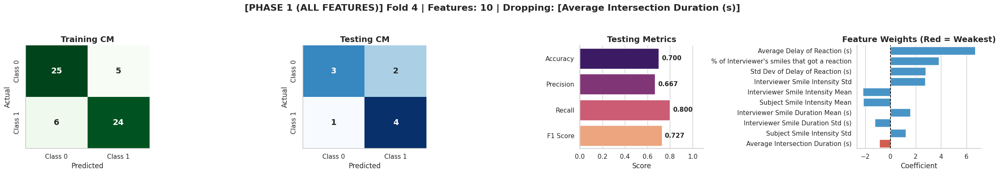

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


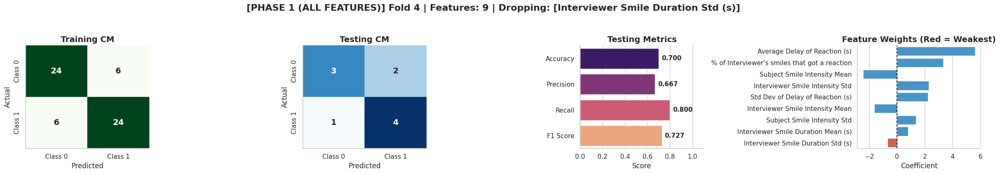

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


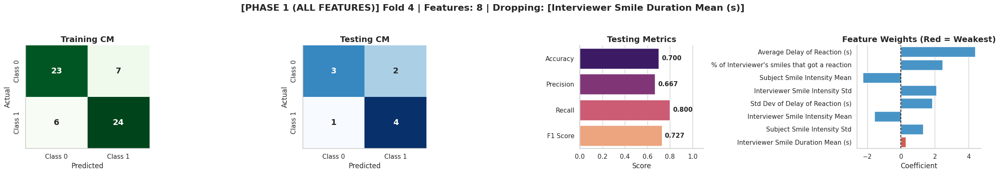

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


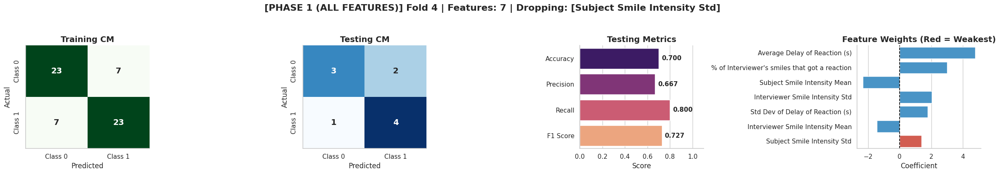

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


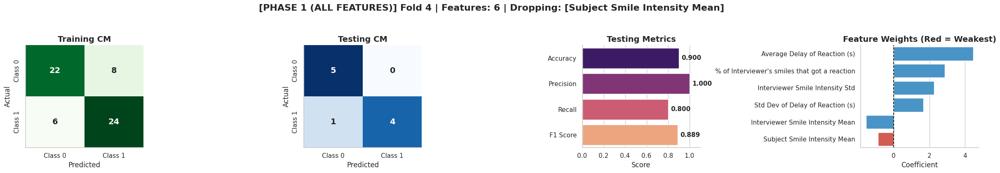

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


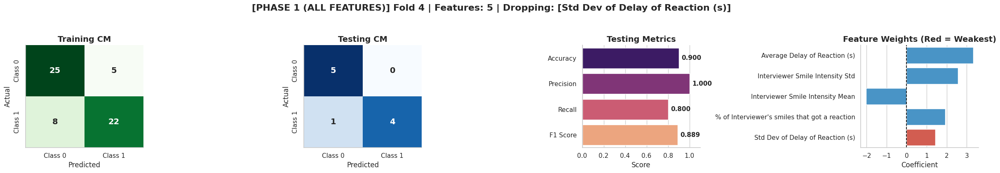

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


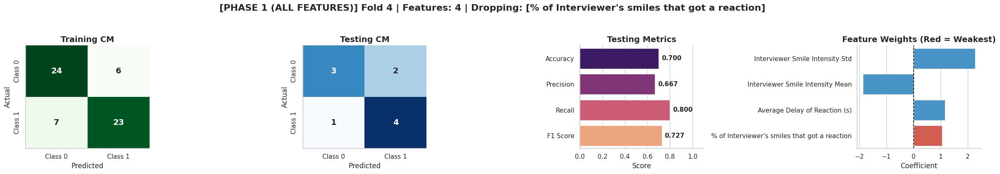

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


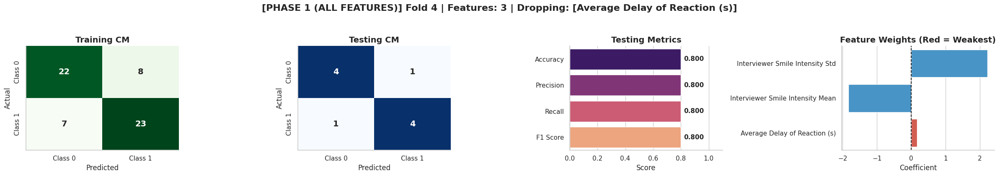

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


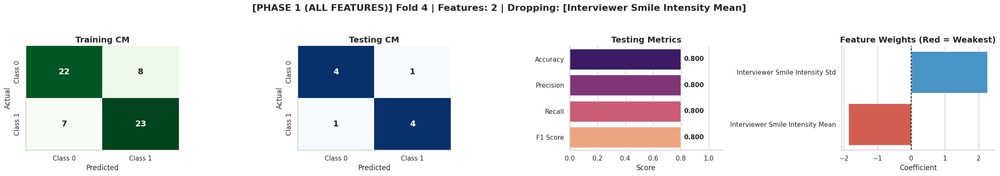

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


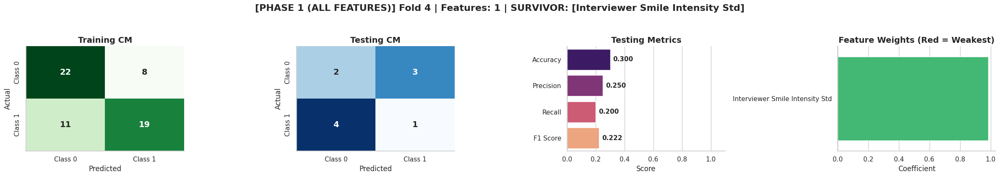


[PHASE 1 (ALL FEATURES)] STARTING FOLD 5 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


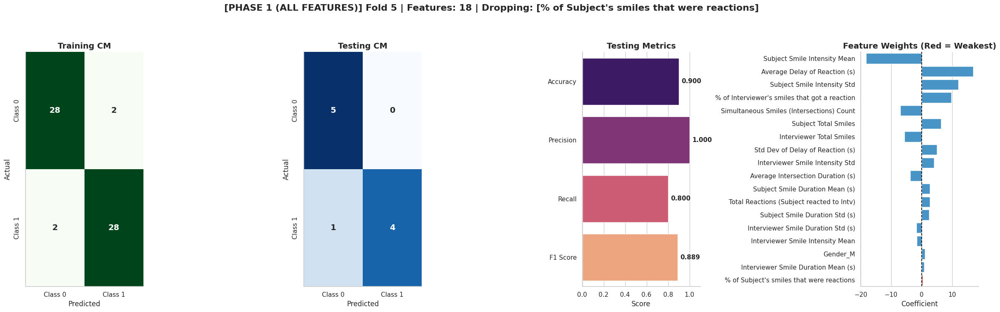

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


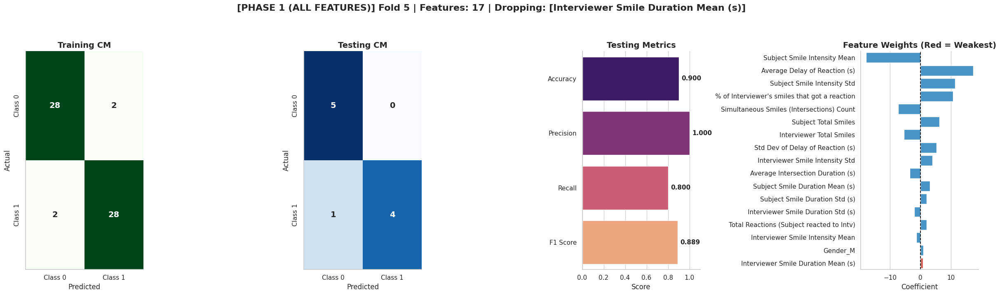

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


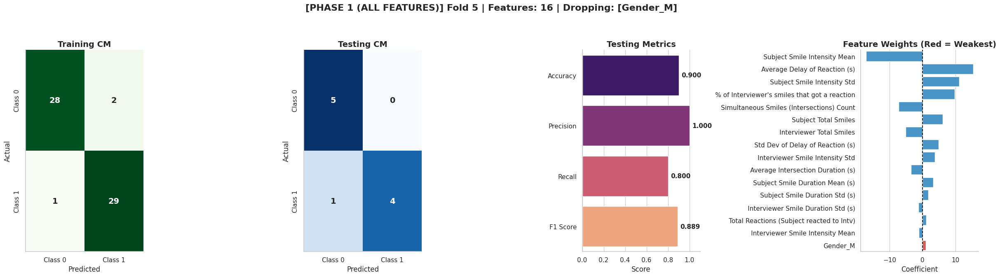

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


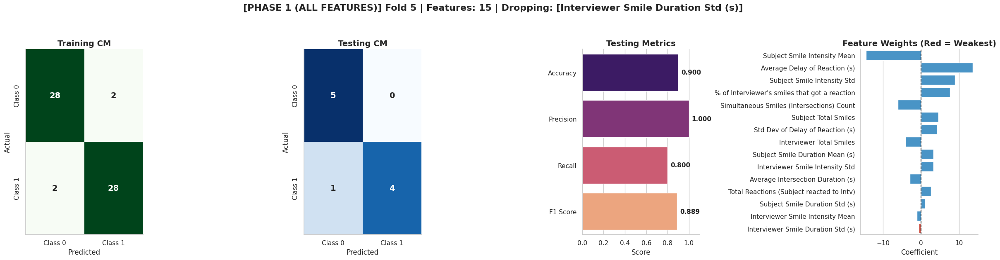

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


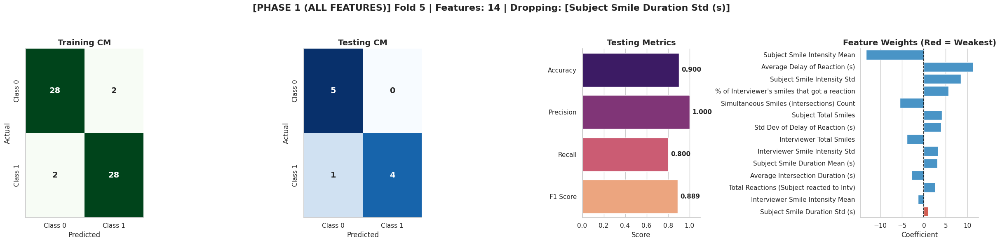

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


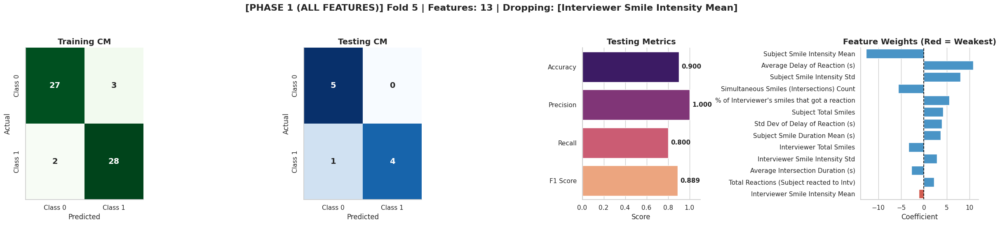

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


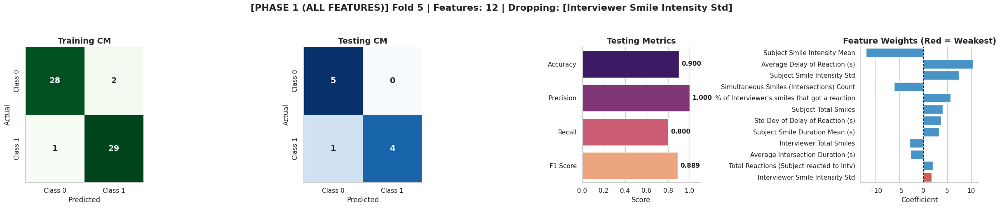

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


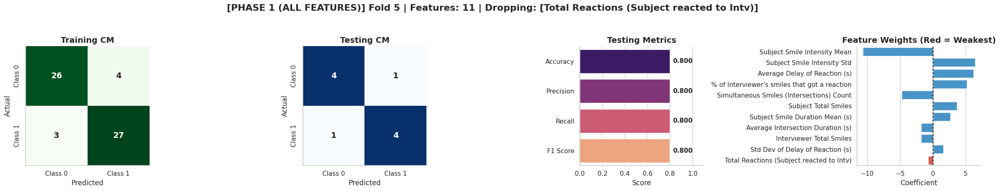

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


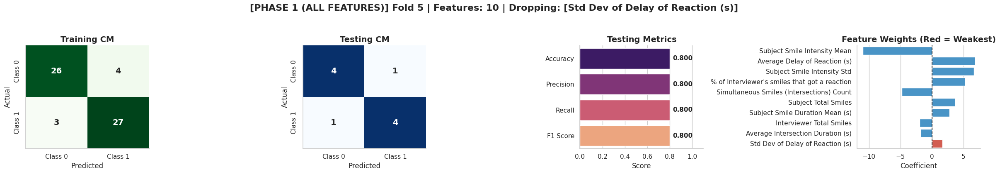

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


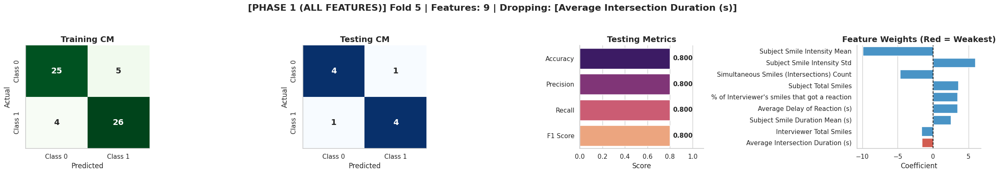

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


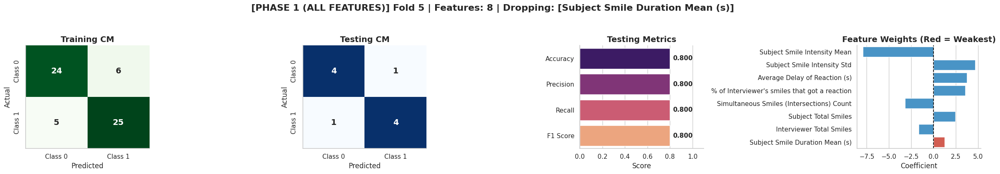

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


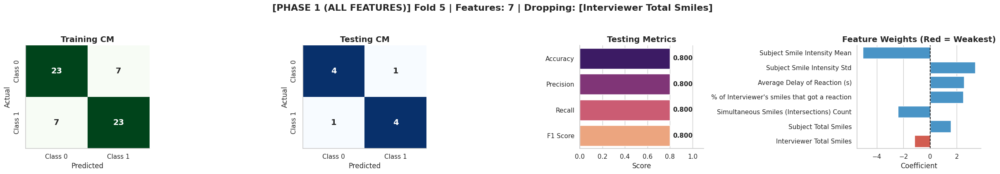

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


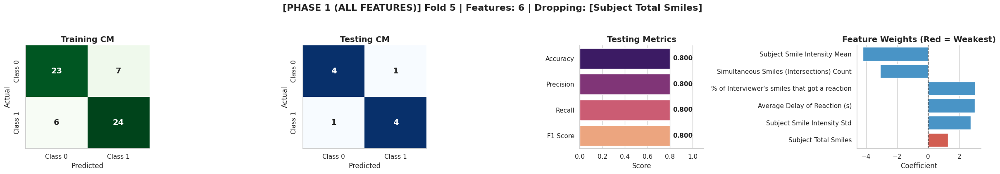

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


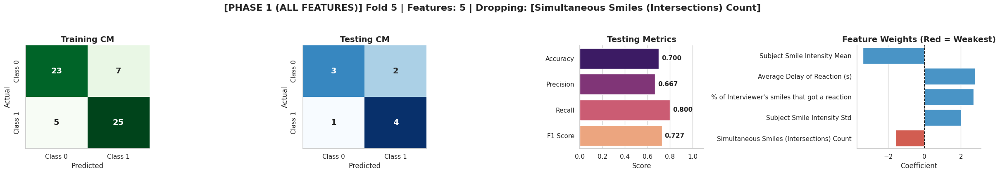

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


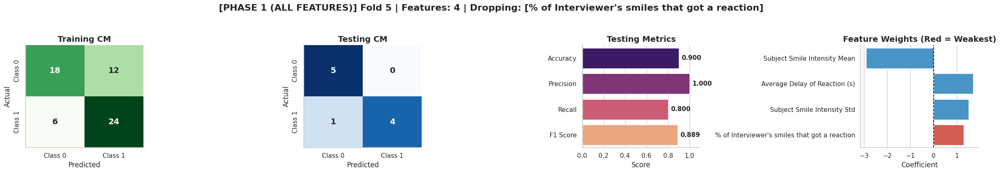

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


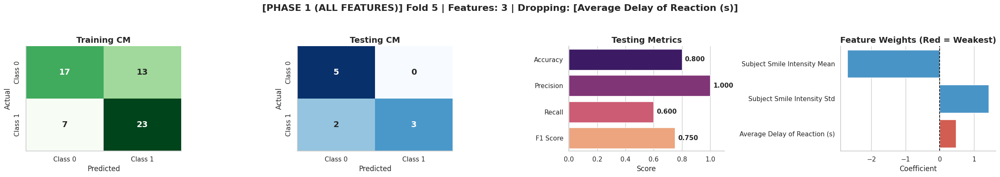

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


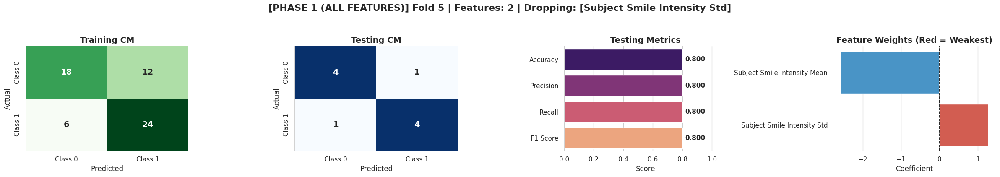

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


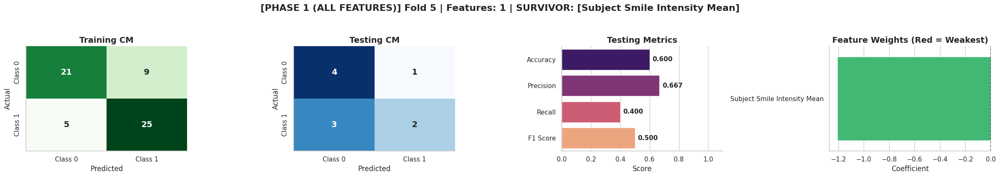


[PHASE 1 (ALL FEATURES)] STARTING FOLD 6 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


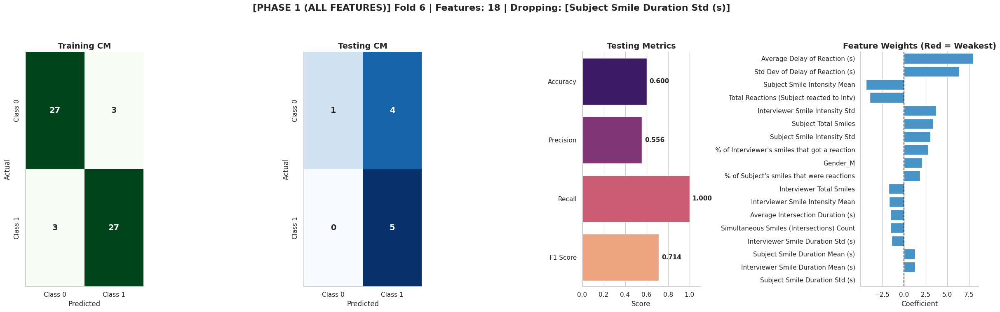

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


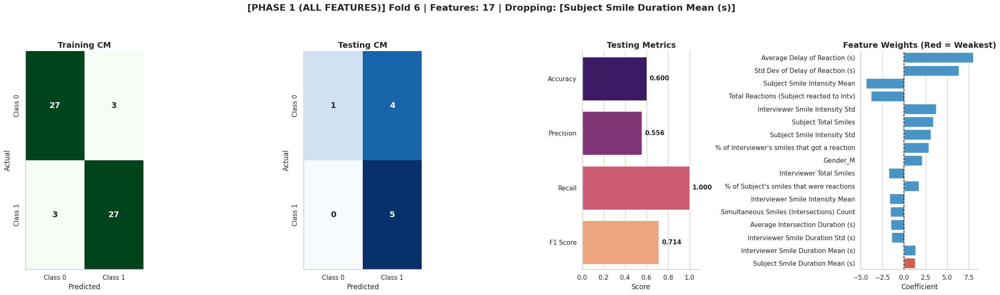

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


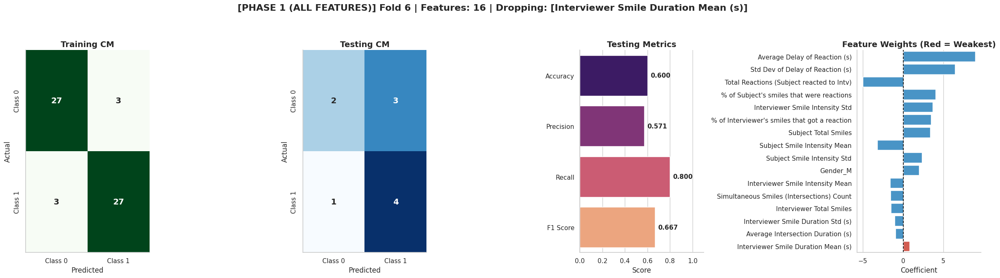

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


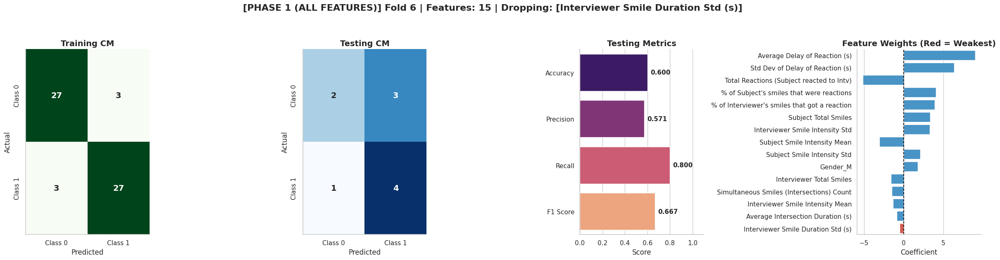

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


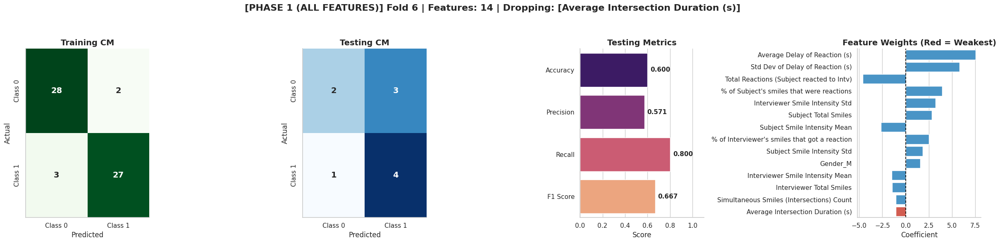

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


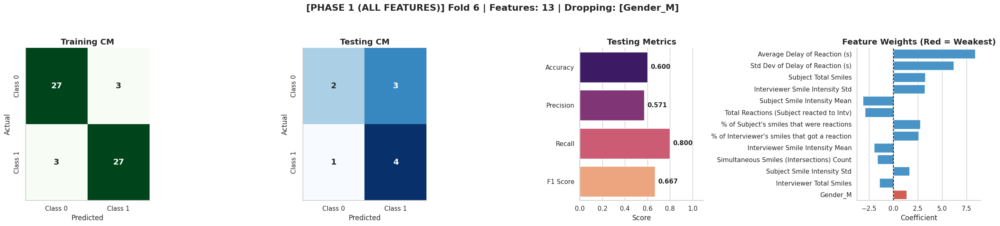

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


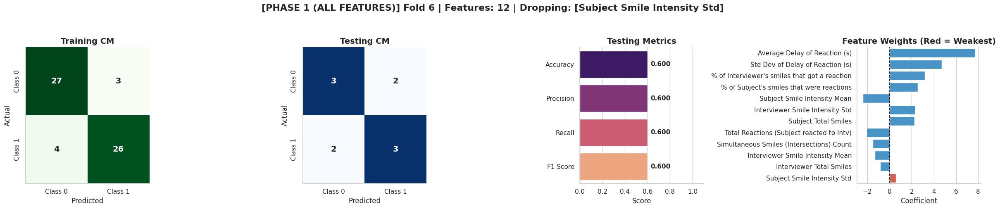

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


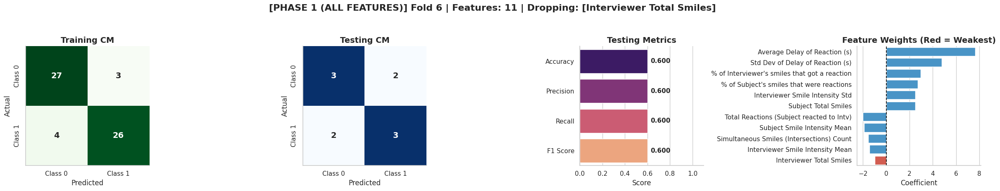

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


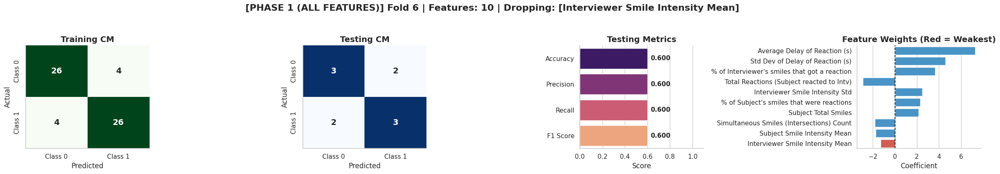

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


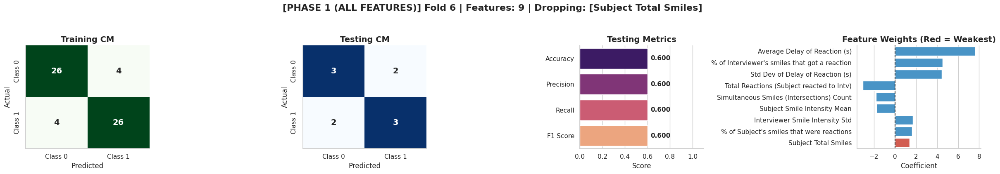

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


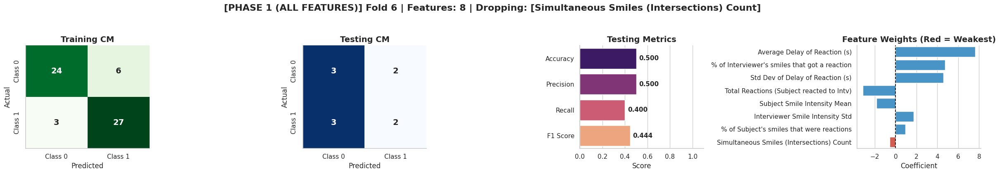

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


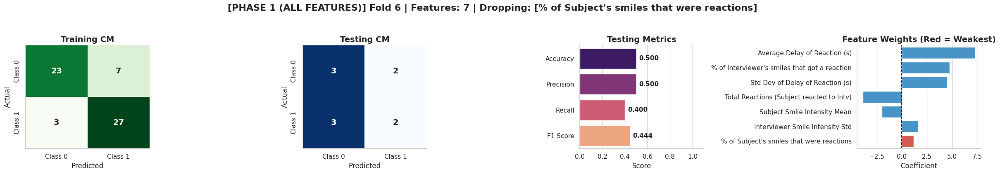

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


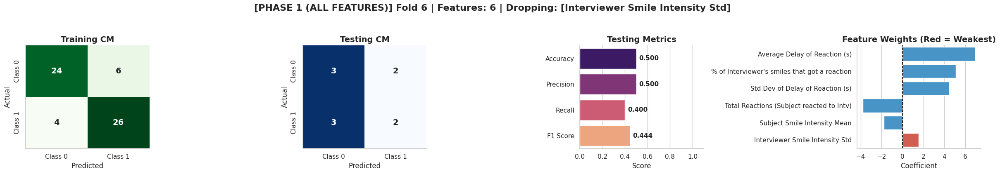

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


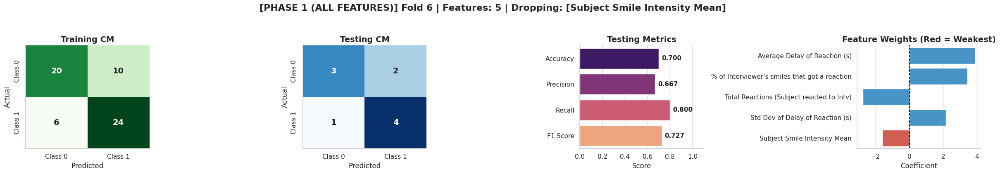

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


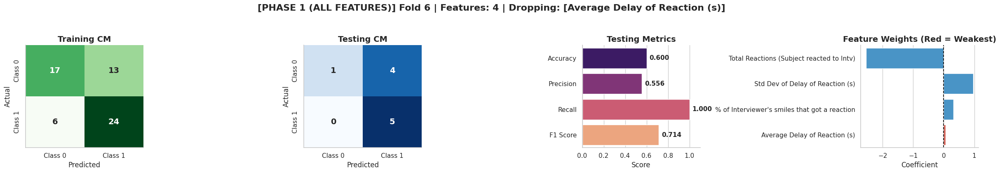

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


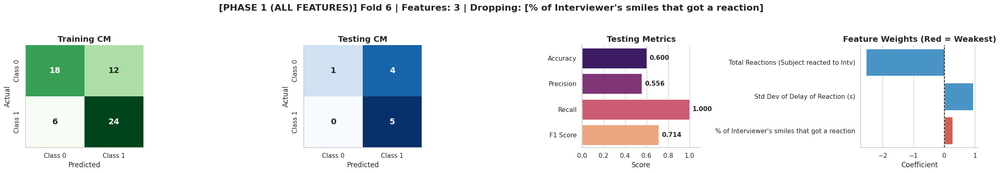

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


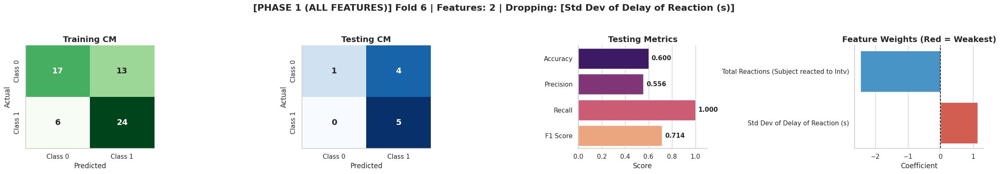

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


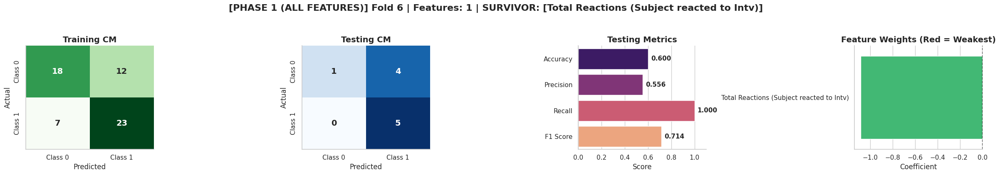


[PHASE 1 (ALL FEATURES)] STARTING FOLD 7 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


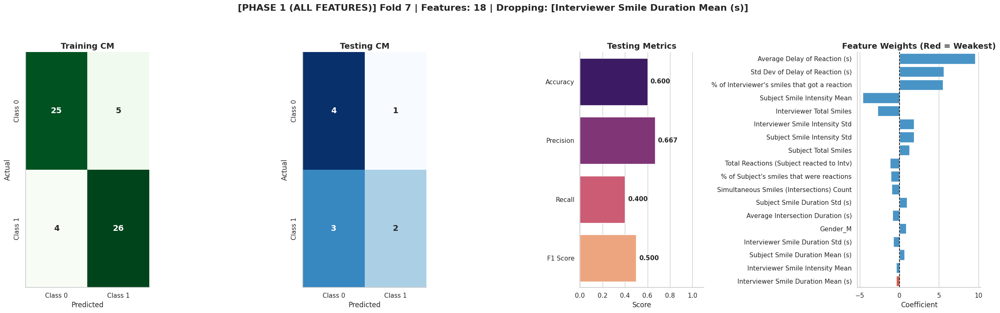

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


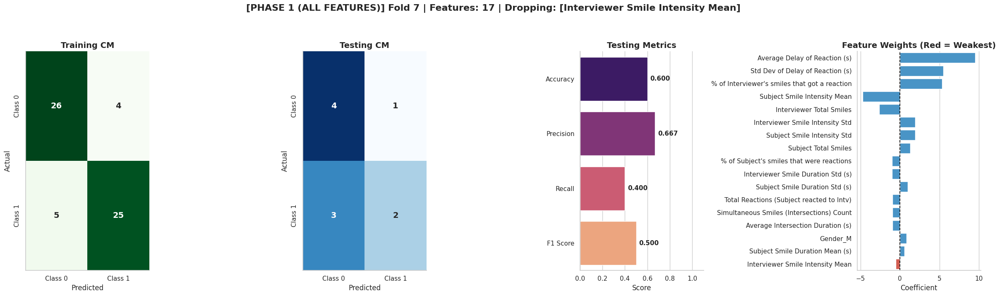

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


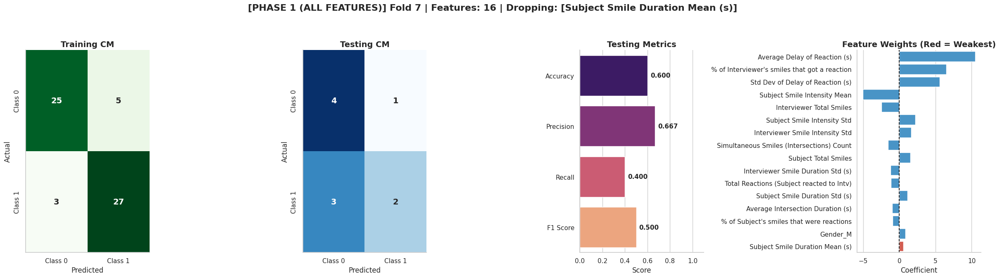

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


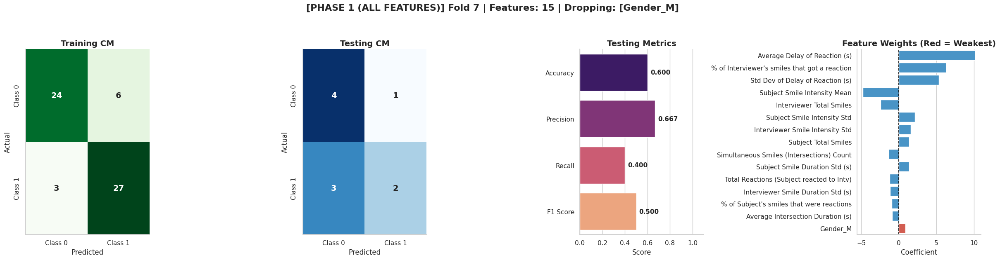

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


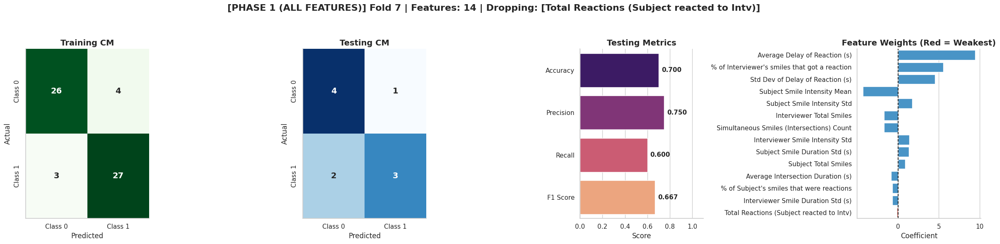

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


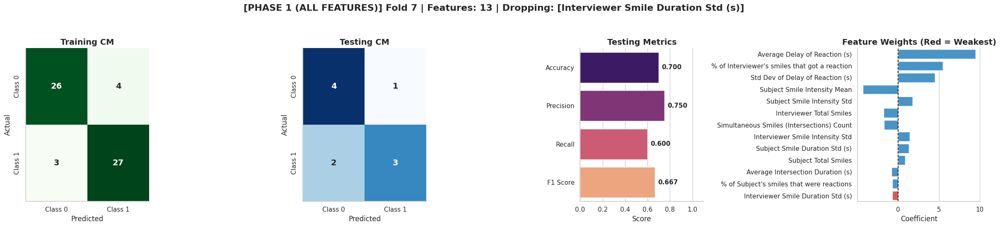

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


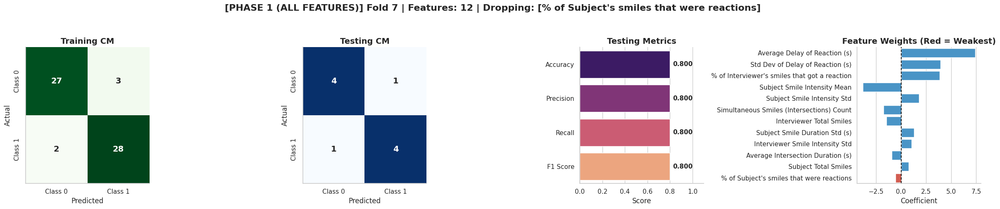

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


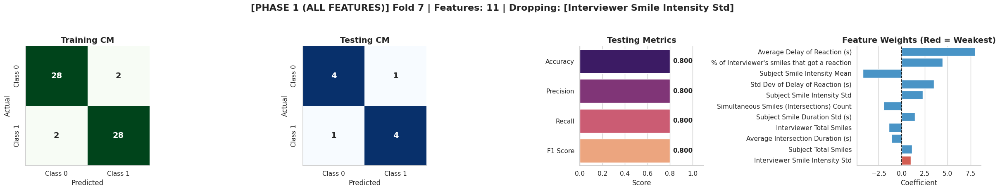

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


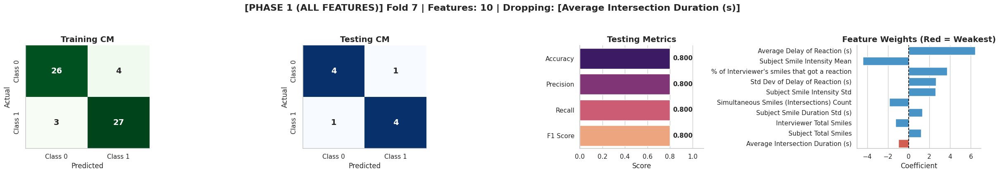

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


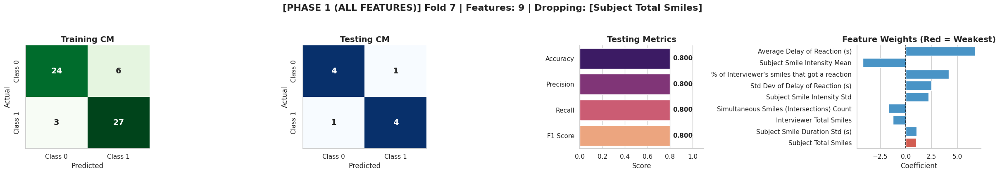

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


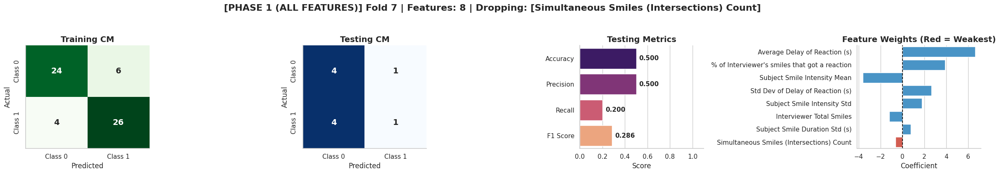

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


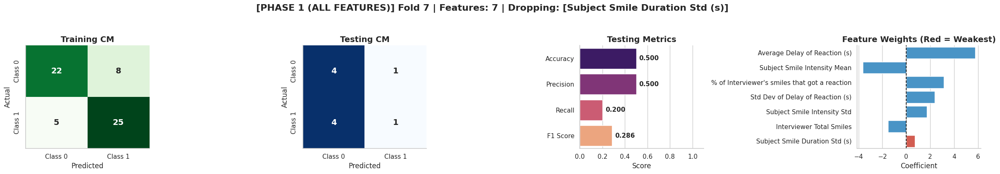

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


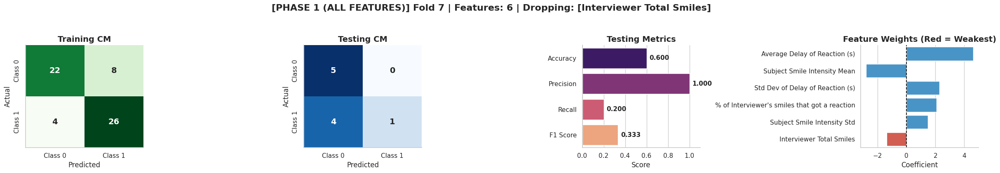

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


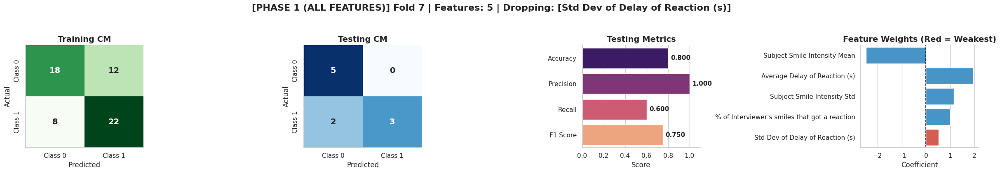

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


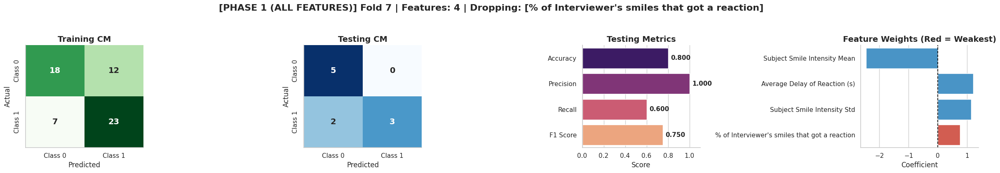

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


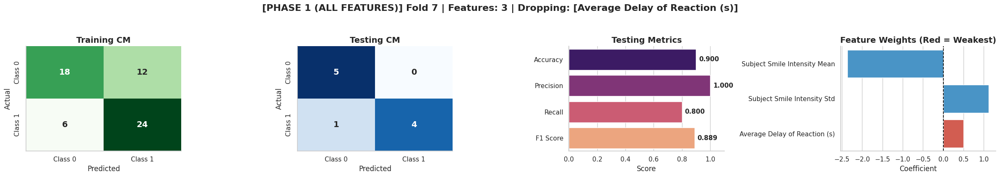

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


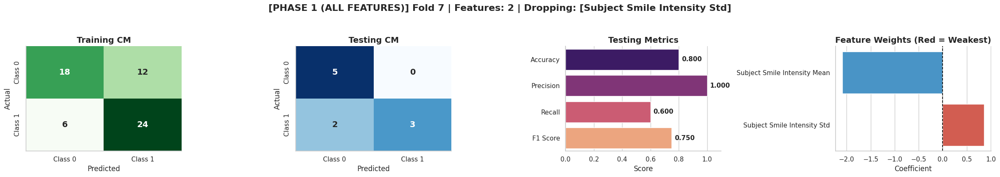

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


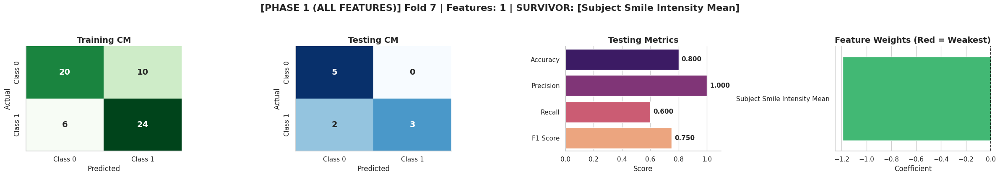

/tmp/ipykernel_82533/2202589265.py:172: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mean_Survival_Score', y=scores_df.index, data=scores_df, palette='magma', ax=axes[1])


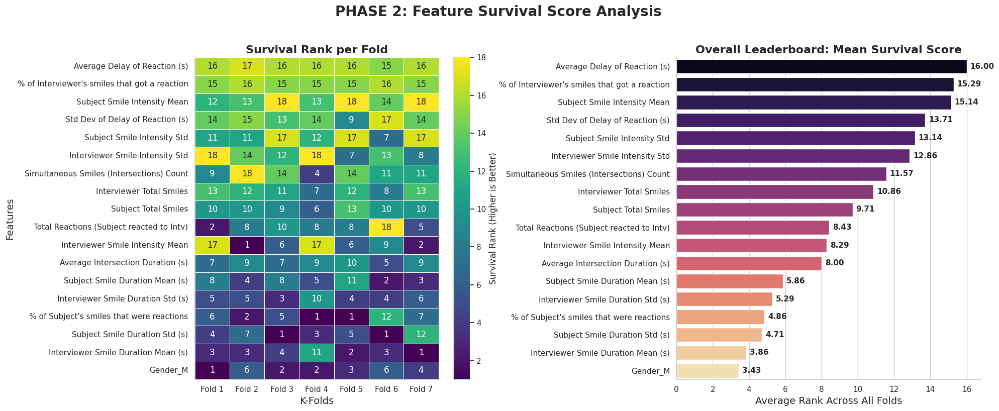


############################################################
PHASE 3: FINAL SHOWDOWN
Features that survived to the end of at least 1 fold: ['Interviewer Smile Intensity Std', 'Subject Smile Intensity Mean', 'Simultaneous Smiles (Intersections) Count', 'Total Reactions (Subject reacted to Intv)']
Applying pruning process exclusively on these 4 features...
############################################################


[PHASE 3 (SUBSET)] STARTING FOLD 1 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


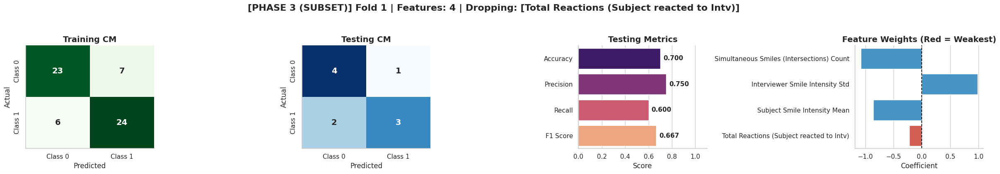

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


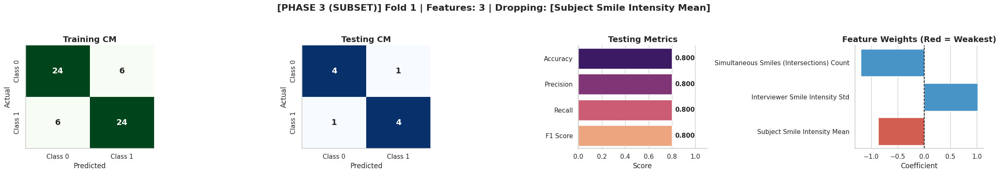

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


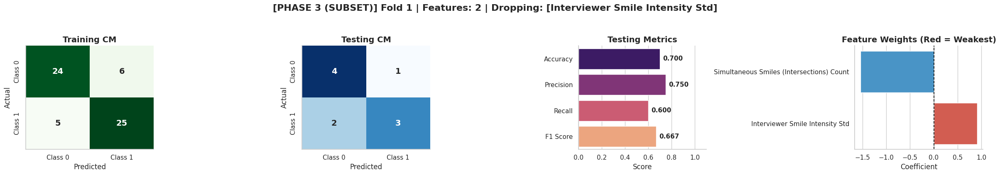

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


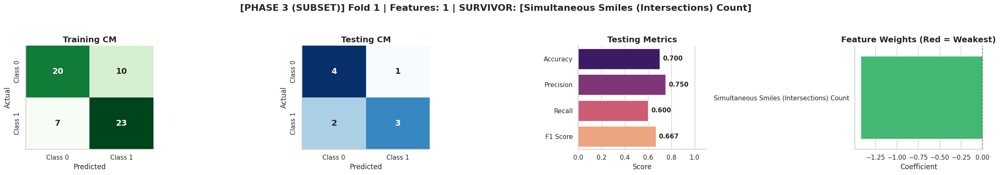


[PHASE 3 (SUBSET)] STARTING FOLD 2 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


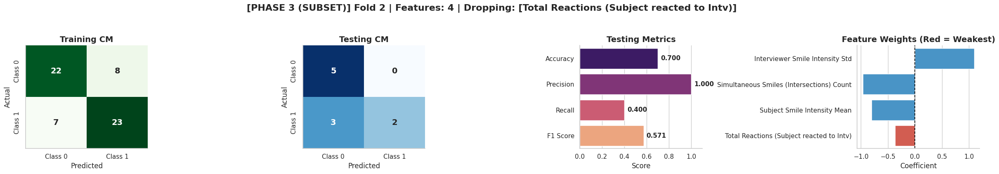

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


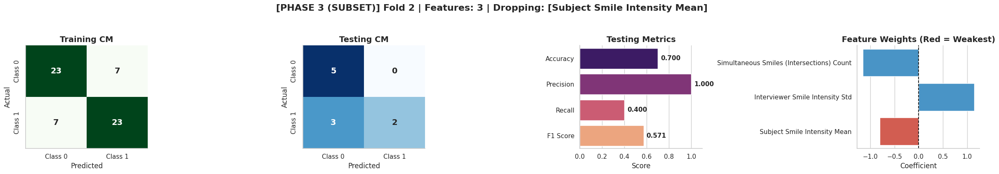

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


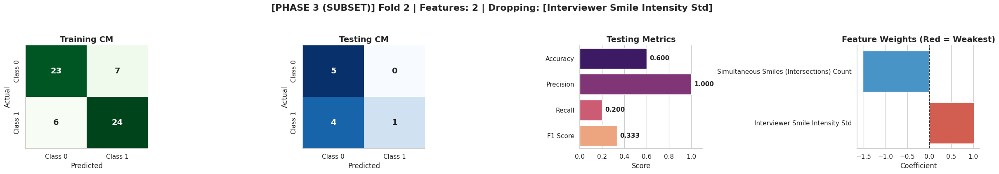

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


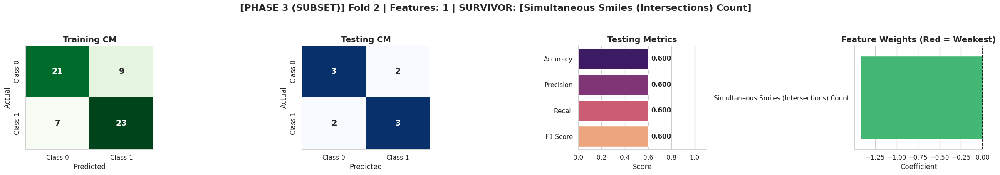


[PHASE 3 (SUBSET)] STARTING FOLD 3 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


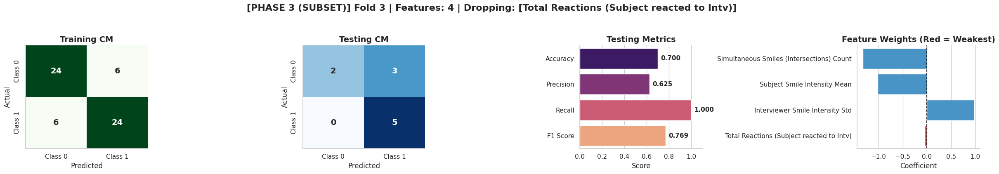

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


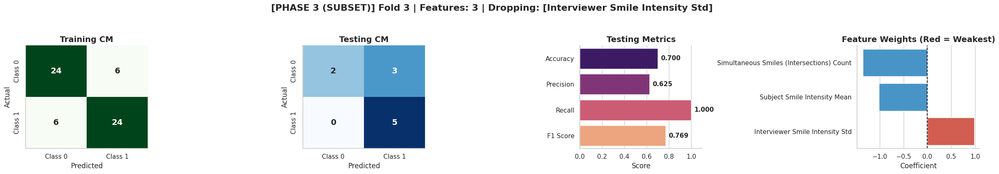

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


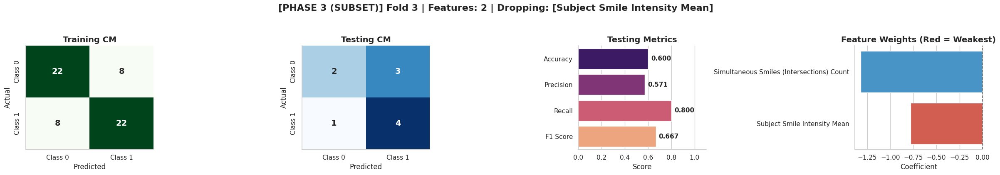

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


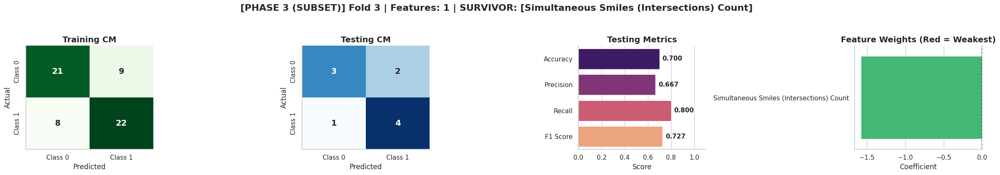


[PHASE 3 (SUBSET)] STARTING FOLD 4 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


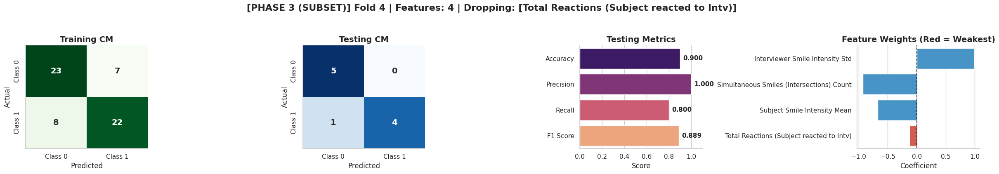

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


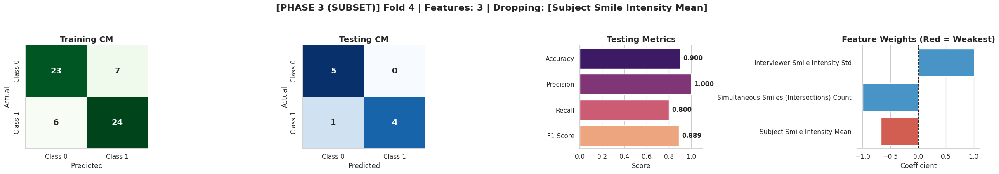

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


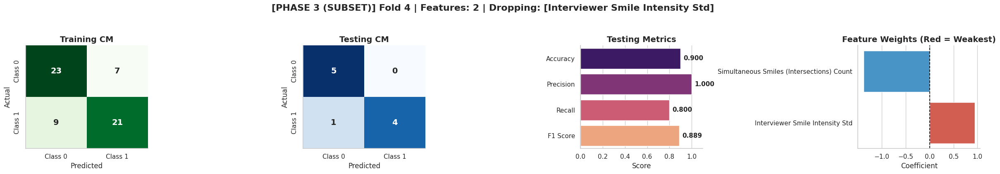

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


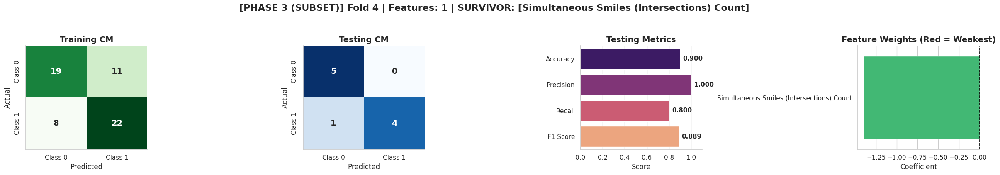


[PHASE 3 (SUBSET)] STARTING FOLD 5 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


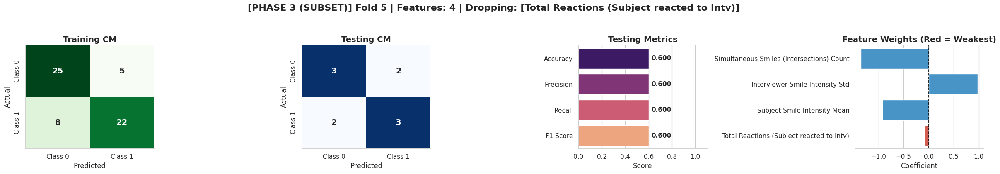

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


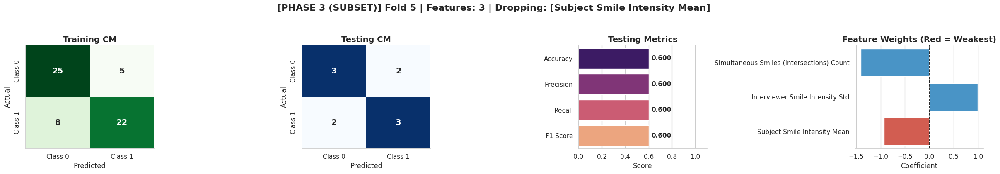

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


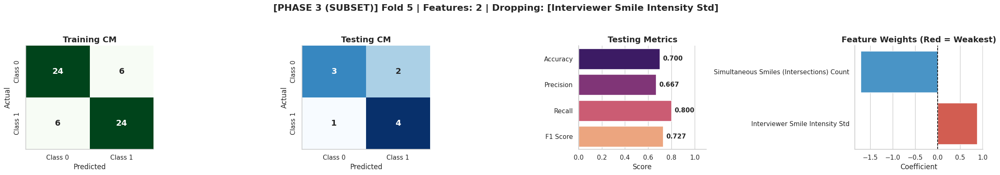

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


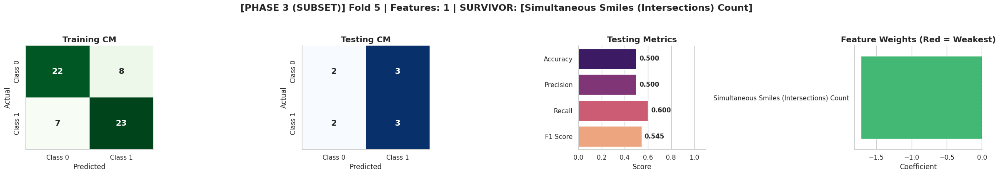


[PHASE 3 (SUBSET)] STARTING FOLD 6 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


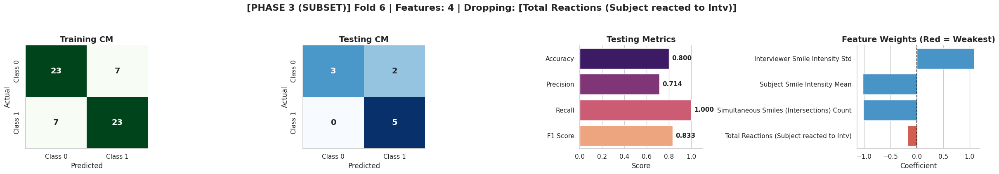

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


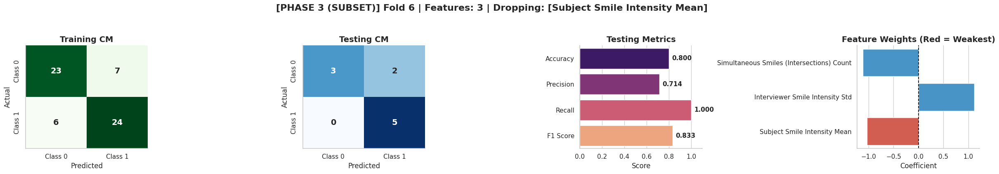

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


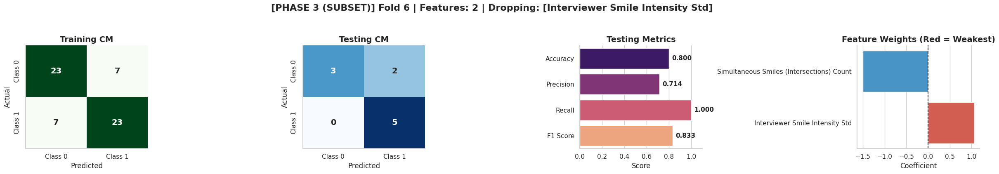

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


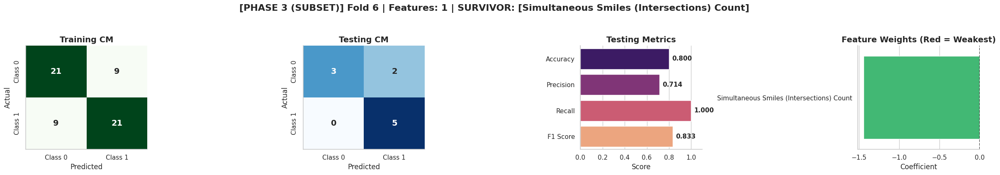


[PHASE 3 (SUBSET)] STARTING FOLD 7 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


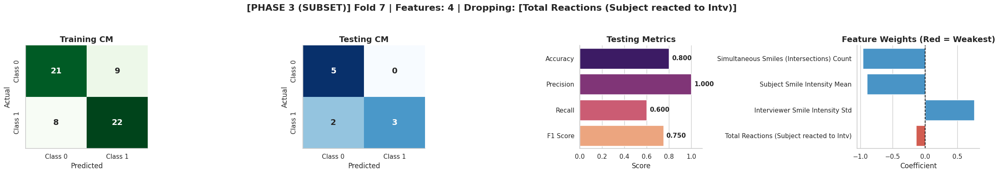

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


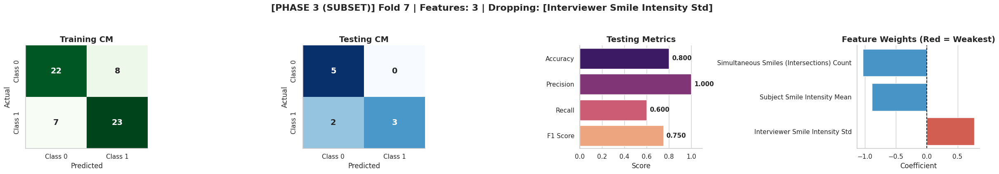

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


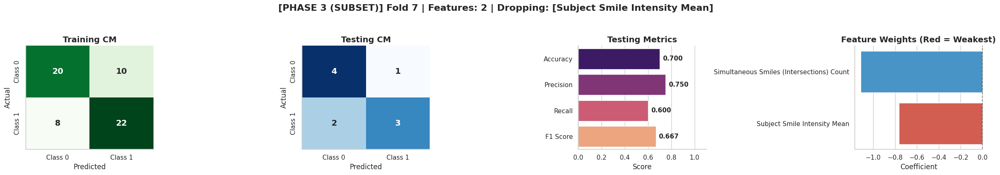

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


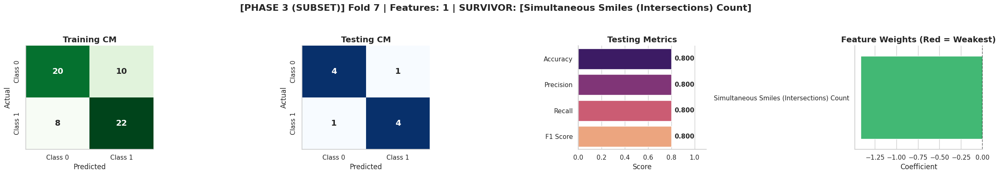

/tmp/ipykernel_82533/2202589265.py:219: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mean_Survival_Score', y=phase3_scores_df.index, data=phase3_scores_df, palette='viridis')


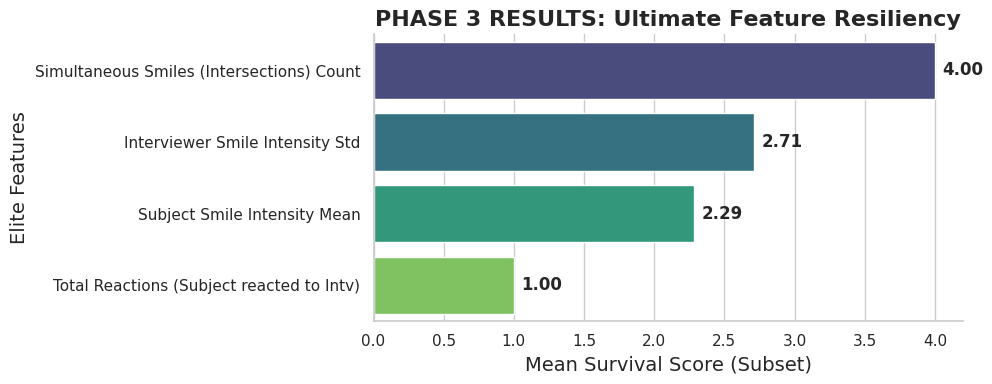

In [13]:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH):
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        
        # Execute the full nested loop
        evaluate_nested_pruning(X=X_scaled, y=y, K_FOLDS=7, use_l1=False, C_value=0)

# Method2

<>:105: SyntaxWarning: invalid escape sequence '\s'
<>:105: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_82533/222143668.py:105: SyntaxWarning: invalid escape sequence '\s'
  axes[2].set_title(f'Feature Weights (Green = Top $\sqrt{{n}}$ Picked)', fontsize=14, fontweight='bold')
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


Preparing data...
Preparation complete: 70 subjects processed.

PHASE 1: K-FOLD FEATURE SELECTION (Top 8 features per fold)


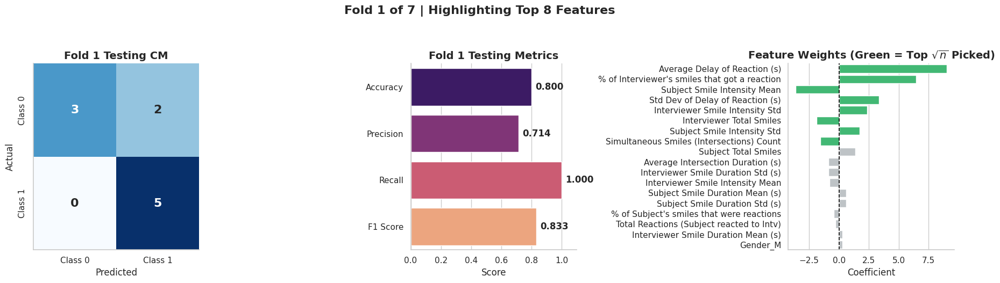

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


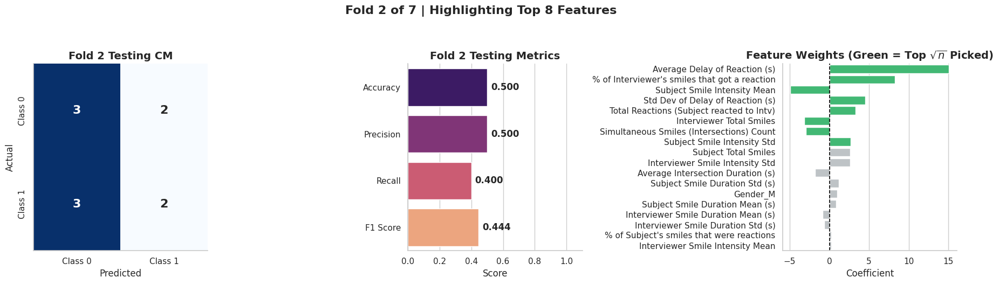

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


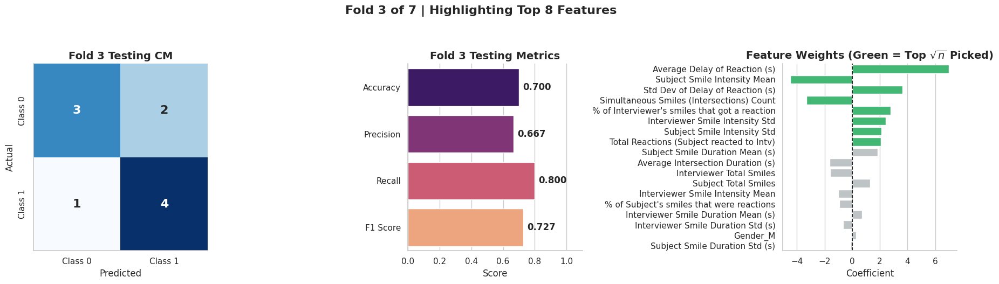

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


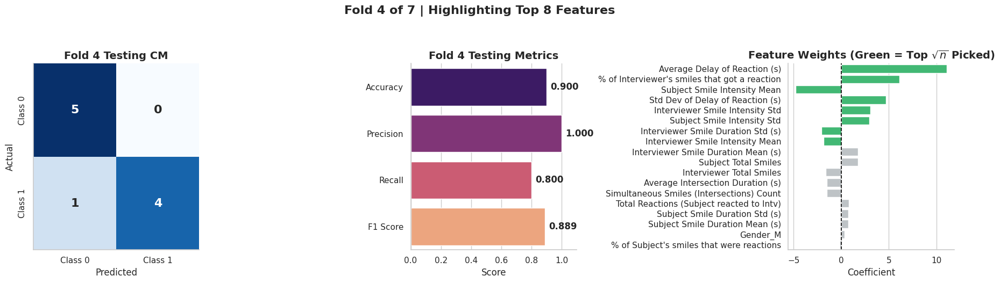

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


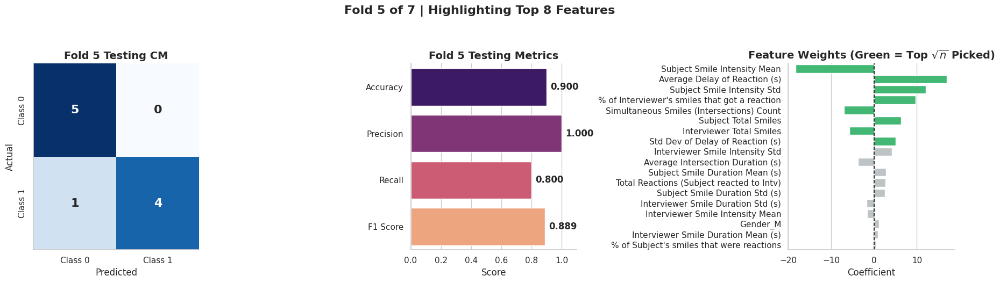

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


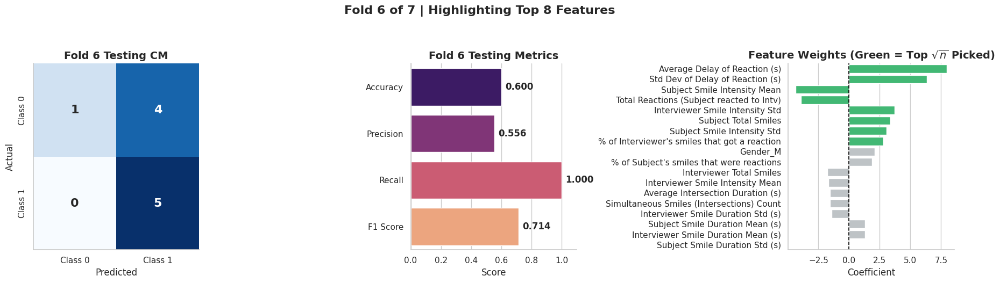

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


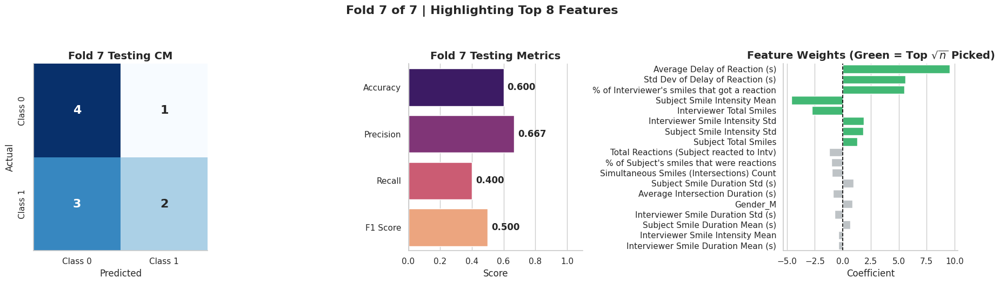


PHASE 2 & 3: GLOBAL TRAINING
Total Unique Features Selected by the Folds: 12



/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


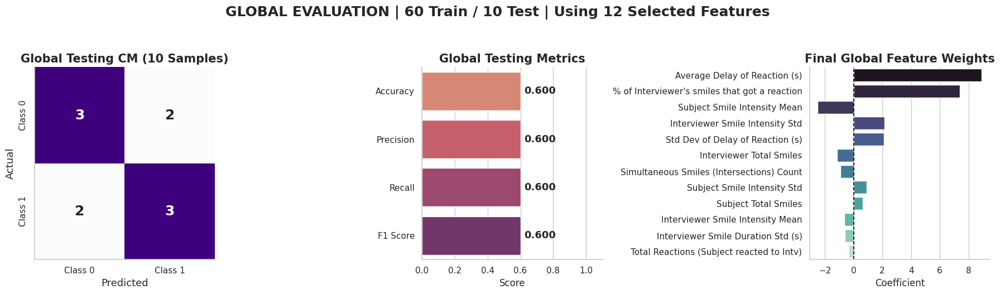

/tmp/ipykernel_82533/222143668.py:211: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Average_Rank', y=ranks_df.index, data=ranks_df,


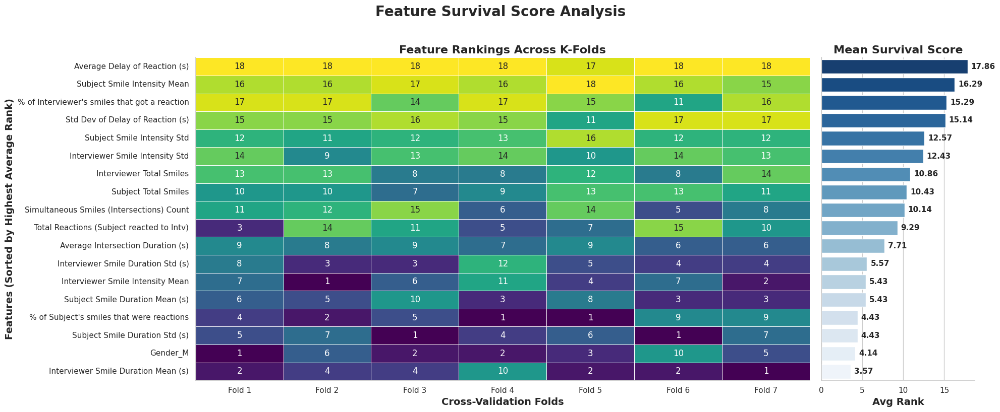

In [14]:
def evaluate_sqrt_n_feature_selection(X, y, K_FOLDS=7, C_value=1.0, max_iter=10000):
    """
    Phase 1: 7-Fold CV to extract top sqrt(n) features per fold.
    Phase 2: Join all extracted features into a unique subset.
    Phase 3: Train globally on 60 samples, test on 10 samples using the subset.
    Phase 4: Display a matrix ranking features across all folds (Highest Weight = Highest Index).
    """
    sns.set_theme(style="whitegrid", palette="muted")
    
    # --- Configuration ---
    n_samples = len(X)
    top_k = int(np.round(np.sqrt(n_samples))) # sqrt(70) ~ 8 features
    
    if C_value == 0 or C_value is None:
        model_params = {'penalty': None, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}
    else:
        model_params = {'penalty': 'l2', 'C': C_value, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}

    log_reg = LogisticRegression(**model_params)
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # Set to store all unique features picked across all 7 folds
    all_picked_features = set()
    
    # Dictionary to store the rank of features in each fold
    fold_ranks_history = {}
    
    print(f"\n{'='*70}")
    print(f"PHASE 1: K-FOLD FEATURE SELECTION (Top {top_k} features per fold)")
    print(f"{'='*70}")

    # =========================================================================
    # PHASE 1: K-Fold Loop
    # =========================================================================
    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        
        # Train model
        log_reg.fit(X_tr, y_tr)
        y_te_pred = log_reg.predict(X_te)
        
        # Calculate Metrics
        test_cm = confusion_matrix(y_te, y_te_pred, labels=[0, 1])
        acc = accuracy_score(y_te, y_te_pred)
        prec = precision_score(y_te, y_te_pred, zero_division=0)
        rec = recall_score(y_te, y_te_pred, zero_division=0)
        f1 = f1_score(y_te, y_te_pred, zero_division=0)
        
        test_metrics = pd.DataFrame({
            "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
            "Score": [acc, prec, rec, f1]
        })
        
        # Extract Coefficients and sort by absolute value
        coefs = log_reg.coef_[0]
        abs_coefs = np.abs(coefs)
        
        # Calculate ranks: ascending=True means Highest Weight = Highest Rank (e.g., 17)
        feature_ranks = pd.Series(abs_coefs).rank(ascending=True, method='min').astype(int)
        fold_ranks_history[f"Fold {fold}"] = dict(zip(X.columns, feature_ranks))
        
        # Find the indices of the top_k features
        top_indices = np.argsort(abs_coefs)[-top_k:]
        picked_features_for_fold = X.columns[top_indices].tolist()
        
        # Add them to the global tracking set
        all_picked_features.update(picked_features_for_fold)
        
        # Setup DataFrame for plotting weights
        iter_df = pd.DataFrame({
            'Feature': X.columns,
            'Coefficient': coefs,
            'Abs_Coef': abs_coefs,
            'Picked': [feat in picked_features_for_fold for feat in X.columns]
        }).sort_values(by='Abs_Coef', ascending=False)
        
        # Color palette: Green if picked, Grey if ignored
        custom_palette = {feat: '#2ecc71' if picked else '#bdc3c7' 
                          for feat, picked in zip(iter_df['Feature'], iter_df['Picked'])}
        
        # --- PER-FOLD PLOT ---
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        fig.suptitle(f'Fold {fold} of {K_FOLDS} | Highlighting Top {top_k} Features', 
                     fontsize=16, fontweight='bold', y=1.05)
        
        # Plot 1: Test CM
        sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                    annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[0].set_title(f'Fold {fold} Testing CM', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Predicted', fontsize=12)
        axes[0].set_ylabel('Actual', fontsize=12)
        
        # Plot 2: Test Metrics
        sns.barplot(x='Score', y='Metric', data=test_metrics, ax=axes[1], hue='Metric', palette='magma', legend=False)
        axes[1].set_title(f'Fold {fold} Testing Metrics', fontsize=14, fontweight='bold')
        axes[1].set_xlim(0, 1.1)
        axes[1].set_ylabel('')
        for i in axes[1].containers:
            axes[1].bar_label(i, fmt='%.3f', padding=5, size=12, weight='bold')
            
        # Plot 3: Feature Weights (Highlighted)
        sns.barplot(x='Coefficient', y='Feature', data=iter_df, ax=axes[2], hue='Feature', palette=custom_palette, legend=False)
        axes[2].set_title(f'Feature Weights (Green = Top $\sqrt{{n}}$ Picked)', fontsize=14, fontweight='bold')
        axes[2].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
        axes[2].set_ylabel('')
        
        sns.despine()
        plt.tight_layout()
        plt.show()

    # =========================================================================
    # PHASE 2 & 3: Global Training
    # =========================================================================
    global_features = list(all_picked_features)
    
    print(f"\n{'='*70}")
    print(f"PHASE 2 & 3: GLOBAL TRAINING")
    print(f"Total Unique Features Selected by the Folds: {len(global_features)}")
    print(f"{'='*70}\n")
    
    # Subset data to ONLY the features that were picked by at least one fold
    X_global = X[global_features]
    
    # Split exactly 60 for training, 10 for testing
    X_tr_g, X_te_g, y_tr_g, y_te_g = train_test_split(
        X_global, y, 
        test_size=10, 
        stratify=y, 
        random_state=42
    )
    
    # Train Global Model
    log_reg.fit(X_tr_g, y_tr_g)
    y_te_g_pred = log_reg.predict(X_te_g)
    
    # Calculate Global Metrics
    global_cm = confusion_matrix(y_te_g, y_te_g_pred, labels=[0, 1])
    g_acc = accuracy_score(y_te_g, y_te_g_pred)
    g_prec = precision_score(y_te_g, y_te_g_pred, zero_division=0)
    g_rec = recall_score(y_te_g, y_te_g_pred, zero_division=0)
    g_f1 = f1_score(y_te_g, y_te_g_pred, zero_division=0)
    
    global_metrics = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
        "Score": [g_acc, g_prec, g_rec, g_f1]
    })
    
    global_coefs_df = pd.DataFrame({
        'Feature': X_global.columns,
        'Coefficient': log_reg.coef_[0],
        'Abs_Coef': np.abs(log_reg.coef_[0])
    }).sort_values(by='Abs_Coef', ascending=False)
    
    # --- GLOBAL PLOT ---
    fig_g, axes_g = plt.subplots(1, 3, figsize=(18, max(5, len(global_features)*0.4)))
    fig_g.suptitle(f'GLOBAL EVALUATION | 60 Train / 10 Test | Using {len(global_features)} Selected Features', 
                 fontsize=18, fontweight='bold', y=1.05)
    
    # Global Test CM
    sns.heatmap(global_cm, annot=True, fmt='d', cmap='Purples', ax=axes_g[0],
                annot_kws={"size": 18, "weight": "bold"}, cbar=False,
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    axes_g[0].set_title(f'Global Testing CM (10 Samples)', fontsize=15, fontweight='bold')
    axes_g[0].set_xlabel('Predicted', fontsize=13)
    axes_g[0].set_ylabel('Actual', fontsize=13)
    
    # Global Test Metrics
    sns.barplot(x='Score', y='Metric', data=global_metrics, ax=axes_g[1], hue='Metric', palette='flare', legend=False)
    axes_g[1].set_title(f'Global Testing Metrics', fontsize=15, fontweight='bold')
    axes_g[1].set_xlim(0, 1.1)
    axes_g[1].set_ylabel('')
    for i in axes_g[1].containers:
        axes_g[1].bar_label(i, fmt='%.3f', padding=5, size=13, weight='bold')
        
    # Global Final Weights
    sns.barplot(x='Coefficient', y='Feature', data=global_coefs_df, ax=axes_g[2], hue='Feature', palette='mako', legend=False)
    axes_g[2].set_title(f'Final Global Feature Weights', fontsize=15, fontweight='bold')
    axes_g[2].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
    axes_g[2].set_ylabel('')
    
    sns.despine()
    plt.tight_layout()
    plt.show()

    # =========================================================================
    # PHASE 4: Feature Ranking Matrix Across All Folds (Highest = Best)
    # =========================================================================
# Convert fold ranks to DataFrame
    ranks_df = pd.DataFrame(fold_ranks_history)
    
    # Calculate an Average Rank to sort the features (Higher average = better feature)
    ranks_df['Average_Rank'] = ranks_df.mean(axis=1)
    ranks_df = ranks_df.sort_values(by='Average_Rank', ascending=False)
    
    # Create subplots with a width ratio (Heatmap 4x wider than Bar plot)
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={'width_ratios': [4, 1]})
    fig.suptitle('Feature Survival Score Analysis', fontsize=20, fontweight='bold', y=1.02)

    # 1. Heatmap (Left Axis)
    max_rank = len(X.columns)
    sns.heatmap(ranks_df.drop(columns=['Average_Rank']), annot=True, fmt="d", cmap="viridis", 
                cbar=False, linewidths=0.5, ax=axes[0])
    
    axes[0].set_title('Feature Rankings Across K-Folds', fontsize=16, fontweight='bold')
    axes[0].set_xlabel('Cross-Validation Folds', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Features (Sorted by Highest Average Rank)', fontsize=14, fontweight='bold')
    
    # 2. Average Rank Bar Chart (Right Axis)
    sns.barplot(x='Average_Rank', y=ranks_df.index, data=ranks_df, 
                ax=axes[1], palette='Blues_r', orient='h')
    
    axes[1].set_title('Mean Survival Score', fontsize=16, fontweight='bold')
    axes[1].set_xlabel('Avg Rank', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('') # Hide y-labels on the bar plot as they duplicate the heatmap
    axes[1].tick_params(axis='y', which='both', left=False, labelleft=False) # Hide y-axis ticks
    
    # Add values to the bars
    for i in axes[1].containers:
        axes[1].bar_label(i, fmt='%.2f', padding=5, size=11, weight='bold')

    sns.despine()
    plt.tight_layout()
    plt.show()
    
# Example Usage:
if __name__ == "__main__":
    DATA_PATH = '/home/amir/Ados_lab/final_feature_matrix.csv' 
    if os.path.exists(DATA_PATH): 
        df = pd.read_csv(DATA_PATH)
        
        # Prepare Data (Assuming your prepare_data function is loaded)
        X_scaled, y = prepare_data(df)
        
        # Execute the full pipeline
        evaluate_sqrt_n_feature_selection(X=X_scaled, y=y, K_FOLDS=7, C_value=0)

# Method 3

Preparing data...
Preparation complete: 70 subjects processed.

STARTING RECURSIVE FEATURE PRUNING (7-Fold CV)

Processing Fold 1/7...


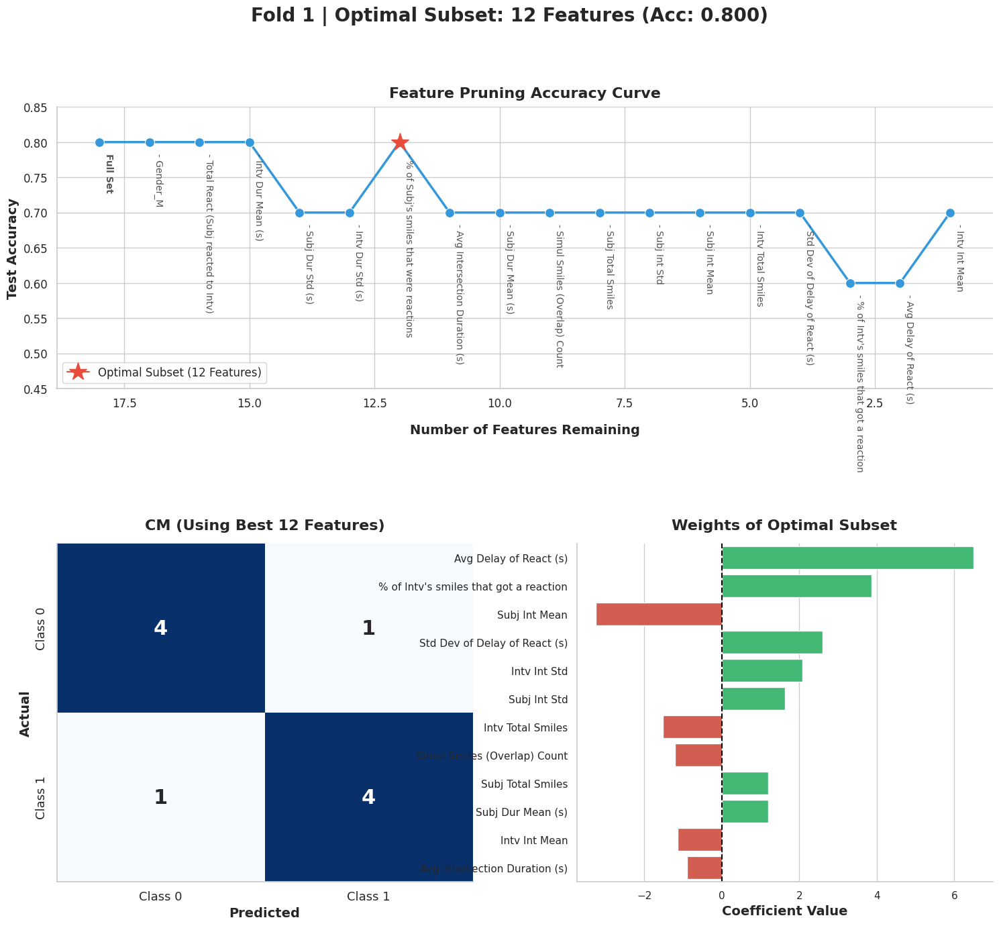

Processing Fold 2/7...


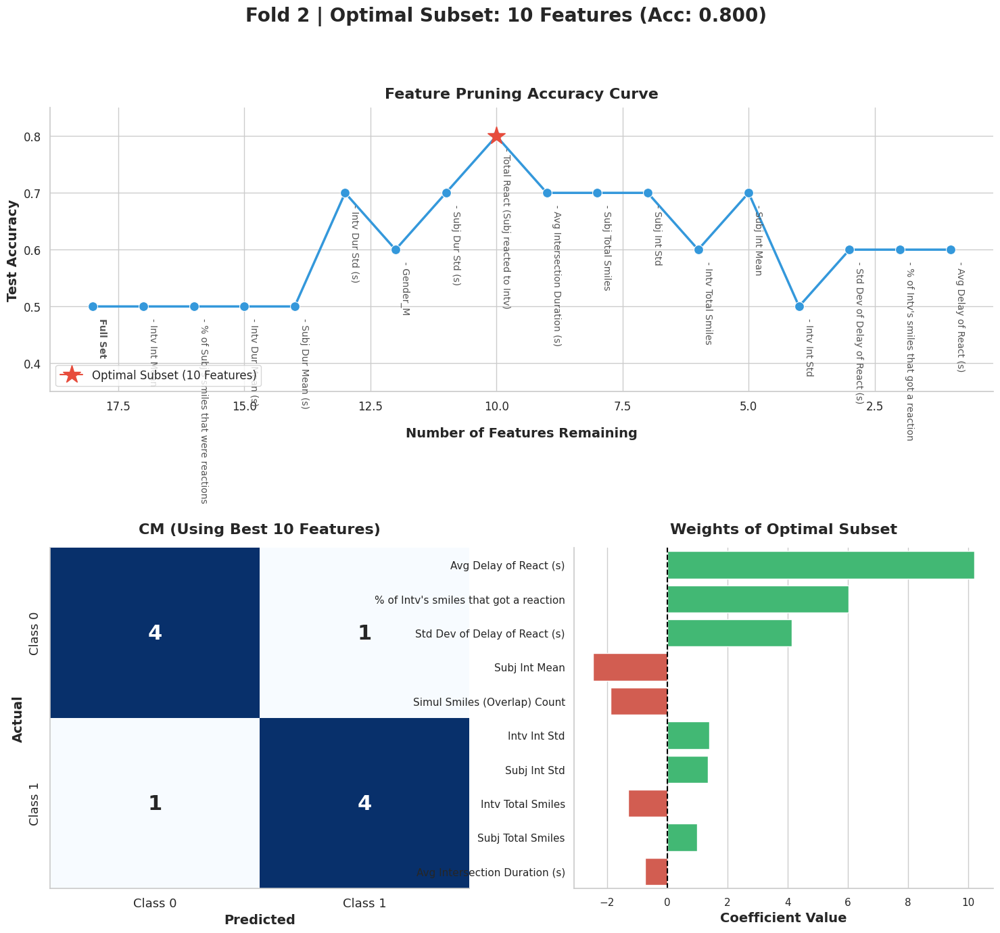

Processing Fold 3/7...


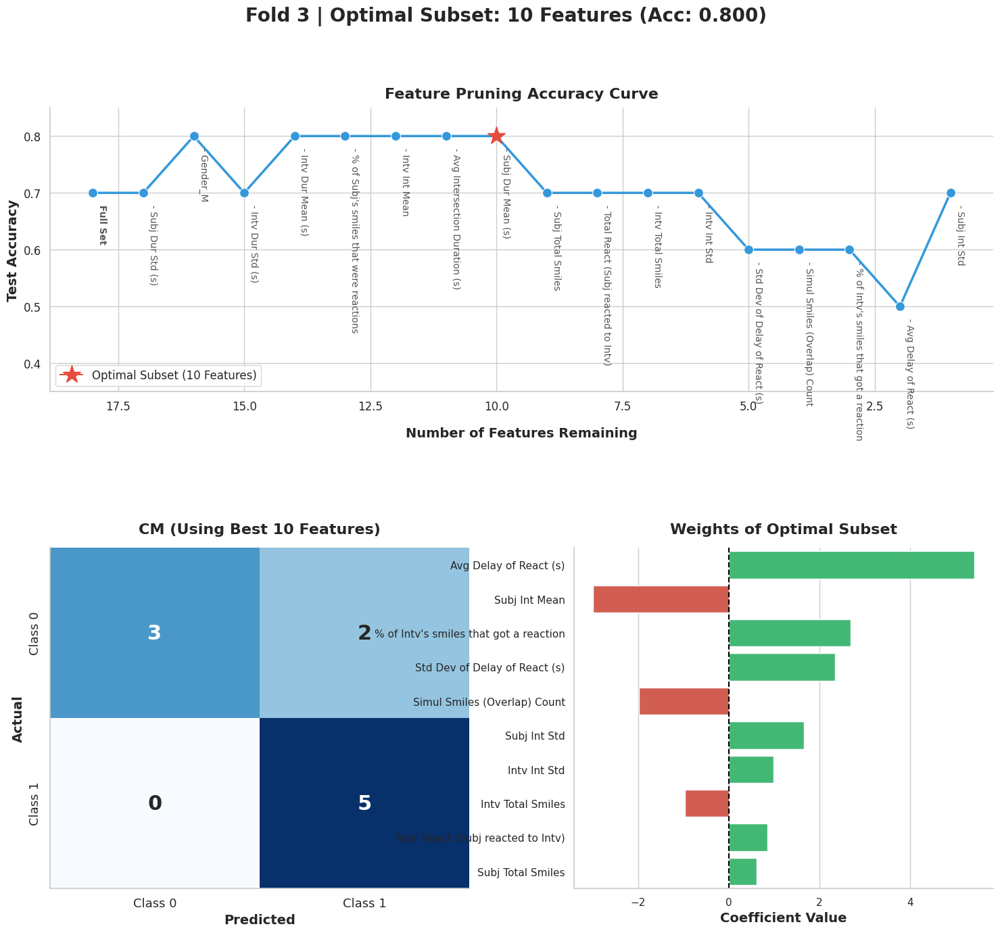

Processing Fold 4/7...


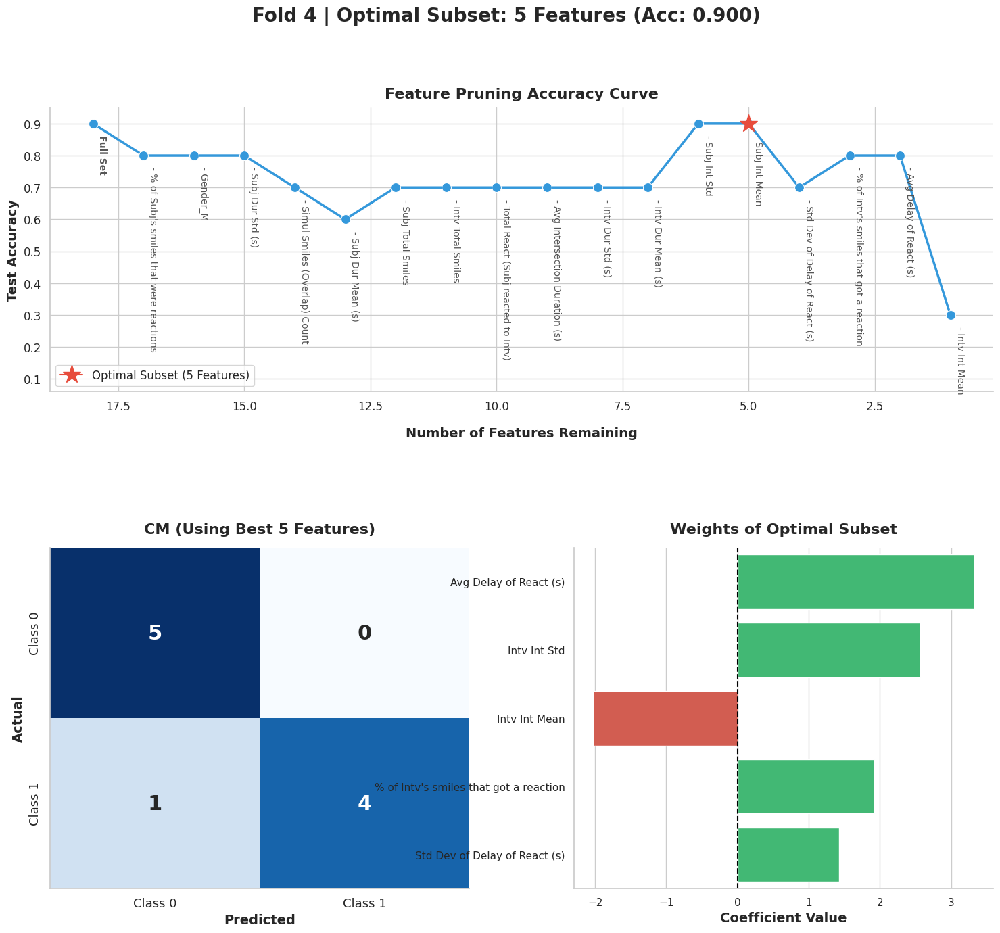

Processing Fold 5/7...


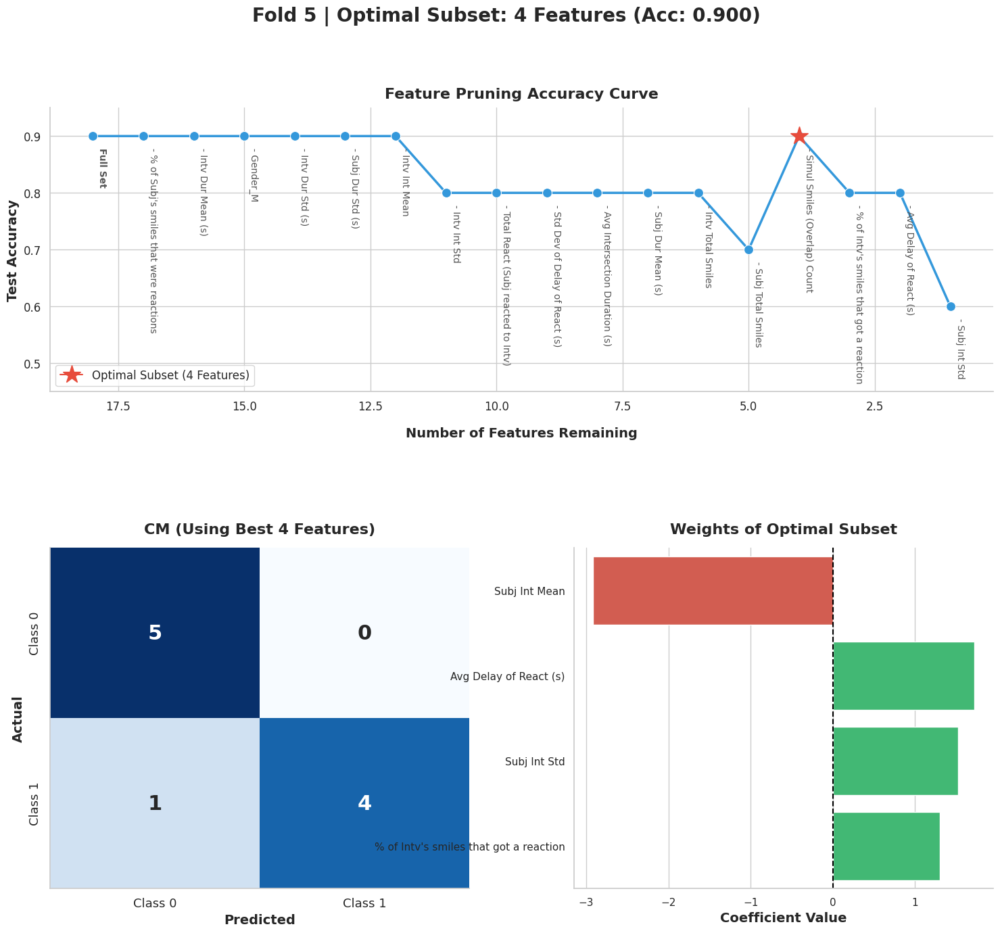

Processing Fold 6/7...


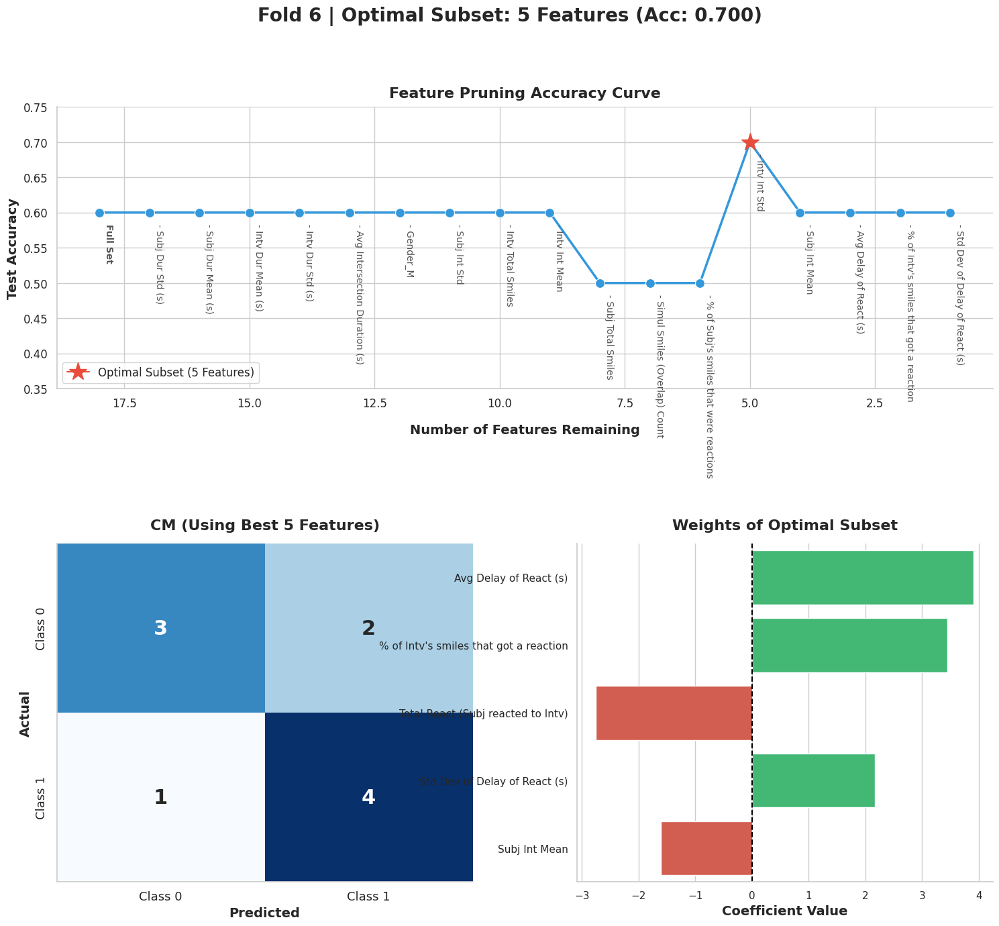

Processing Fold 7/7...


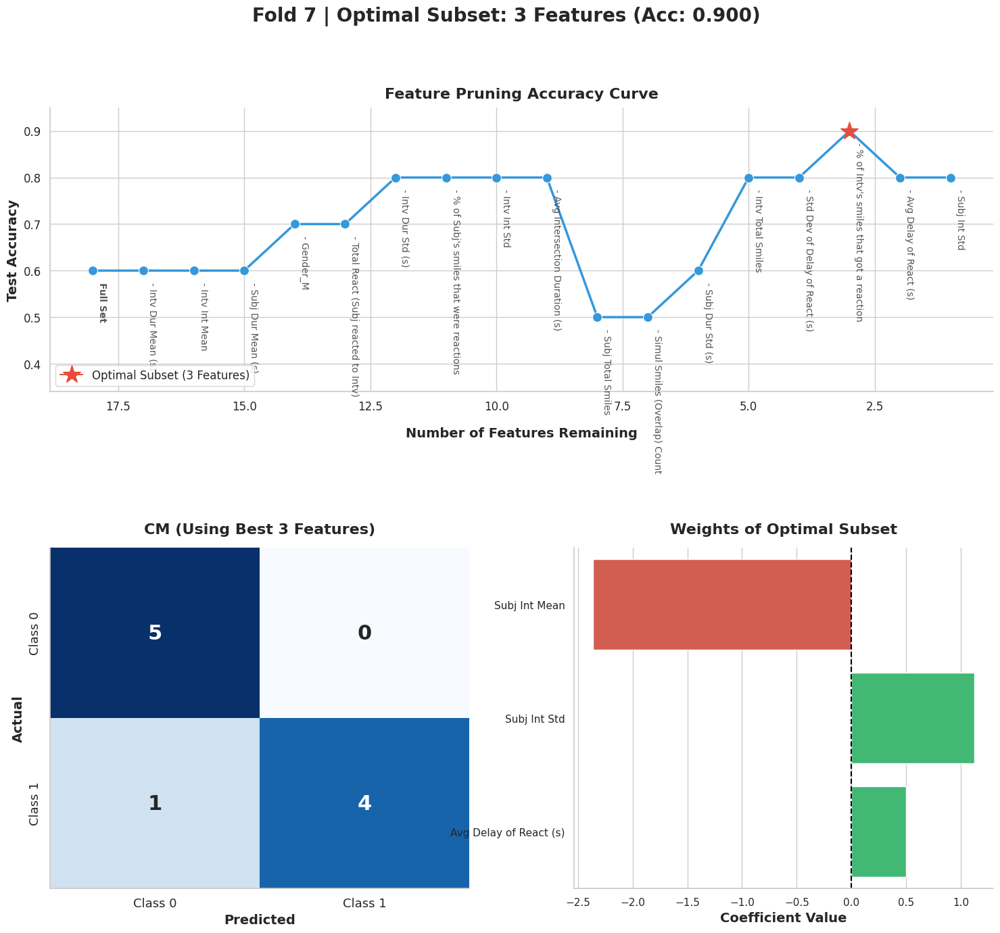

In [15]:
def abbreviate_feature_name(name):
    """Shortens long feature names so they don't overlap on the plot axis."""
    replacements = {
        "Interviewer": "Intv", "Subject": "Subj", "Smile Duration": "Dur",
        "Smile Intensity": "Int", "Average": "Avg", "Simultaneous": "Simul",
        "Intersections": "Overlap", "Reactions": "React", "Reaction": "React"
    }
    for old, new in replacements.items():
        name = name.replace(old, new)
    return name

# =============================================================================
# K-Fold Pruning Algorithm
# =============================================================================
def evaluate_kfold_pruning(X, y, K_FOLDS=7, C_value=1.0, max_iter=10000):
    sns.set_theme(style="whitegrid", palette="muted")
    
    # Fix for scikit-learn 1.8 FutureWarning
    if C_value == 0 or C_value is None:
        model_params = {'C': np.inf, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}
    else:
        model_params = {'C': C_value, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}

    log_reg = LogisticRegression(**model_params)
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    fold_best_features = {}
    
    print(f"\n{'='*80}")
    print(f"STARTING RECURSIVE FEATURE PRUNING ({K_FOLDS}-Fold CV)")
    print(f"{'='*80}\n")

    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        print(f"Processing Fold {fold}/{K_FOLDS}...")
        
        X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        
        current_features = list(X.columns)
        
        pruning_history_x = []
        pruning_history_y = []
        dropped_history = [] # NEW: Tracks what feature was dropped to reach this point
        
        best_acc = -1
        best_features = []
        best_cm = None
        best_coefs = None
        
        last_dropped = "All Features" # The very first point has all features
        
        # --- The Pruning Loop ---
        while len(current_features) > 0:
            log_reg.fit(X_tr[current_features], y_tr)
            y_te_pred = log_reg.predict(X_te[current_features])
            
            acc = accuracy_score(y_te, y_te_pred)
            
            pruning_history_x.append(len(current_features))
            pruning_history_y.append(acc)
            dropped_history.append(last_dropped) # Record what was eliminated to get here
            
            if acc >= best_acc:
                best_acc = acc
                best_features = list(current_features)
                best_cm = confusion_matrix(y_te, y_te_pred, labels=[0, 1])
                
                best_coefs = pd.DataFrame({
                    'Feature': current_features,
                    'Coefficient': log_reg.coef_[0],
                    'Abs_Coef': np.abs(log_reg.coef_[0])
                }).sort_values(by='Abs_Coef', ascending=False)
                
                best_coefs['Display_Feature'] = best_coefs['Feature'].apply(abbreviate_feature_name)
            
            # Find the weakest feature to eliminate in the NEXT round
            current_coefs = np.abs(log_reg.coef_[0])
            weakest_feature_idx = np.argmin(current_coefs)
            weakest_feature_name = current_features[weakest_feature_idx]
            
            last_dropped = weakest_feature_name # Save it for the next iteration's annotation
            current_features.remove(weakest_feature_name)
            
        fold_best_features[f"Fold_{fold}"] = best_features
            
        # --- Plotting the 2x2 Dashboard for the Fold ---
        fig = plt.figure(figsize=(18, 15))
        gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2], wspace=0.25, hspace=0.5)
        
        fig.suptitle(f'Fold {fold} | Optimal Subset: {len(best_features)} Features (Acc: {best_acc:.3f})', 
                     fontsize=20, fontweight='bold', y=0.98)
        
        ax_curve = fig.add_subplot(gs[0, 0:2])
        ax_cm = fig.add_subplot(gs[1, 0])
        ax_weights = fig.add_subplot(gs[1, 1])
        
        sns.lineplot(x=pruning_history_x, y=pruning_history_y, marker='o', 
                     color='#3498db', linewidth=2.5, markersize=10, ax=ax_curve)
        
        ax_curve.plot(len(best_features), best_acc, marker='*', color='#e74c3c', markersize=20, 
                      label=f'Optimal Subset ({len(best_features)} Features)', zorder=5)
        
        ax_curve.invert_xaxis()
        ax_curve.set_title('Feature Pruning Accuracy Curve', fontsize=16, fontweight='bold', pad=10)
        ax_curve.set_xlabel('Number of Features Remaining', fontsize=14, fontweight='bold', labelpad=15)
        ax_curve.set_ylabel('Test Accuracy', fontsize=14, fontweight='bold')
        ax_curve.tick_params(axis='both', labelsize=12)
        ax_curve.legend(loc='lower left', fontsize=12)
        
        # NEW: Dynamically adjust Y-limits so the dropped feature labels don't get cut off at the bottom
        y_min, y_max = min(pruning_history_y), max(pruning_history_y)
        margin = max(0.15, (y_max - y_min) * 0.4) 
        ax_curve.set_ylim(y_min - margin, y_max + 0.05)
        
        # NEW: Annotate each point with the feature that was dropped to reach it
        for x_val, y_val, feat in zip(pruning_history_x, pruning_history_y, dropped_history):
            if feat == "All Features":
                text_label = "Full Set"
            else:
                text_label = f"- {abbreviate_feature_name(feat)}"
                
            ax_curve.annotate(
                text_label,
                xy=(x_val, y_val),
                xytext=(5, -12), # offset slightly right and down
                textcoords="offset points",
                ha="left",
                va="top",
                fontsize=10,
                rotation=-90, # angles text down and to the right
                color="#555555",
                fontweight='bold' if feat == "All Features" else 'normal'
            )
        
        sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', ax=ax_cm,
                    annot_kws={"size": 22, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        ax_cm.set_title(f'CM (Using Best {len(best_features)} Features)', fontsize=16, fontweight='bold', pad=15)
        ax_cm.set_xlabel('Predicted', fontsize=14, fontweight='bold')
        ax_cm.set_ylabel('Actual', fontsize=14, fontweight='bold')
        ax_cm.tick_params(axis='both', labelsize=13)
        
        palette = ['#e74c3c' if c < 0 else '#2ecc71' for c in best_coefs['Coefficient']]
        sns.barplot(x='Coefficient', y='Display_Feature', data=best_coefs, ax=ax_weights, 
                    palette=palette, hue='Display_Feature', legend=False)
        
        ax_weights.set_title(f'Weights of Optimal Subset', fontsize=16, fontweight='bold', pad=15)
        ax_weights.axvline(x=0, color='black', linestyle='--', linewidth=1.5)
        ax_weights.set_ylabel('')
        ax_weights.set_xlabel('Coefficient Value', fontsize=14, fontweight='bold')
        ax_weights.tick_params(axis='y', labelsize=11)
        
        sns.despine()
        plt.tight_layout(pad=2.0)
        plt.show()

    return fold_best_features

# =============================================================================
# Execution
# =============================================================================
fold_best_features = None 
if __name__ == "__main__":
    DATA_PATH = '/home/amir/Ados_lab/final_feature_matrix.csv' 
    if os.path.exists(DATA_PATH): 
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        fold_best_features = evaluate_kfold_pruning(X=X_scaled, y=y, K_FOLDS=7, C_value=0)
    else:
        print(f"File not found: {DATA_PATH}")

In [5]:
fold_best_features

{'Fold_1': ['Interviewer Smile Intensity Std'],
 'Fold_2': ['Subject Smile Intensity Mean',
  'Subject Smile Intensity Std',
  'Simultaneous Smiles (Intersections) Count'],
 'Fold_3': ['Interviewer Smile Intensity Std',
  'Subject Smile Intensity Mean',
  'Subject Smile Intensity Std',
  'Simultaneous Smiles (Intersections) Count'],
 'Fold_4': ['Interviewer Smile Intensity Mean',
  'Interviewer Smile Intensity Std'],
 'Fold_5': ['Subject Smile Intensity Mean', 'Subject Smile Intensity Std'],
 'Fold_6': ['Subject Smile Intensity Mean'],
 'Fold_7': ['Interviewer Smile Intensity Mean',
  'Interviewer Smile Intensity Std']}

Preparing data...
Preparation complete: 70 subjects processed.

EVALUATING FEATURE SETS USING LEAVE-ONE-OUT (Train: 69, Test: 1)

Source  Num_Features  LOO_Accuracy  LOO_Precision  LOO_Recall  LOO_F1_Score
Fold_2             3      0.757143       0.736842    0.800000      0.767123
Fold_3             4      0.757143       0.750000    0.771429      0.760563
Fold_6             1      0.742857       0.729730    0.771429      0.750000
Fold_4             2      0.742857       0.742857    0.742857      0.742857
Fold_7             2      0.742857       0.742857    0.742857      0.742857
Fold_5             2      0.685714       0.658537    0.771429      0.710526
Fold_1             1      0.571429       0.575758    0.542857      0.558824


/tmp/ipykernel_27009/3251571262.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Metric', y='Score', data=plot_data, ax=ax, palette='mako')
/tmp/ipykernel_27009/3251571262.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Metric', y='Score', data=plot_data, ax=ax, palette='mako')
/tmp/ipykernel_27009/3251571262.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Metric', y='Score', data=plot_data, ax=ax, palette='mako')
/tmp/ipykernel_27009/3251571262.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is depre

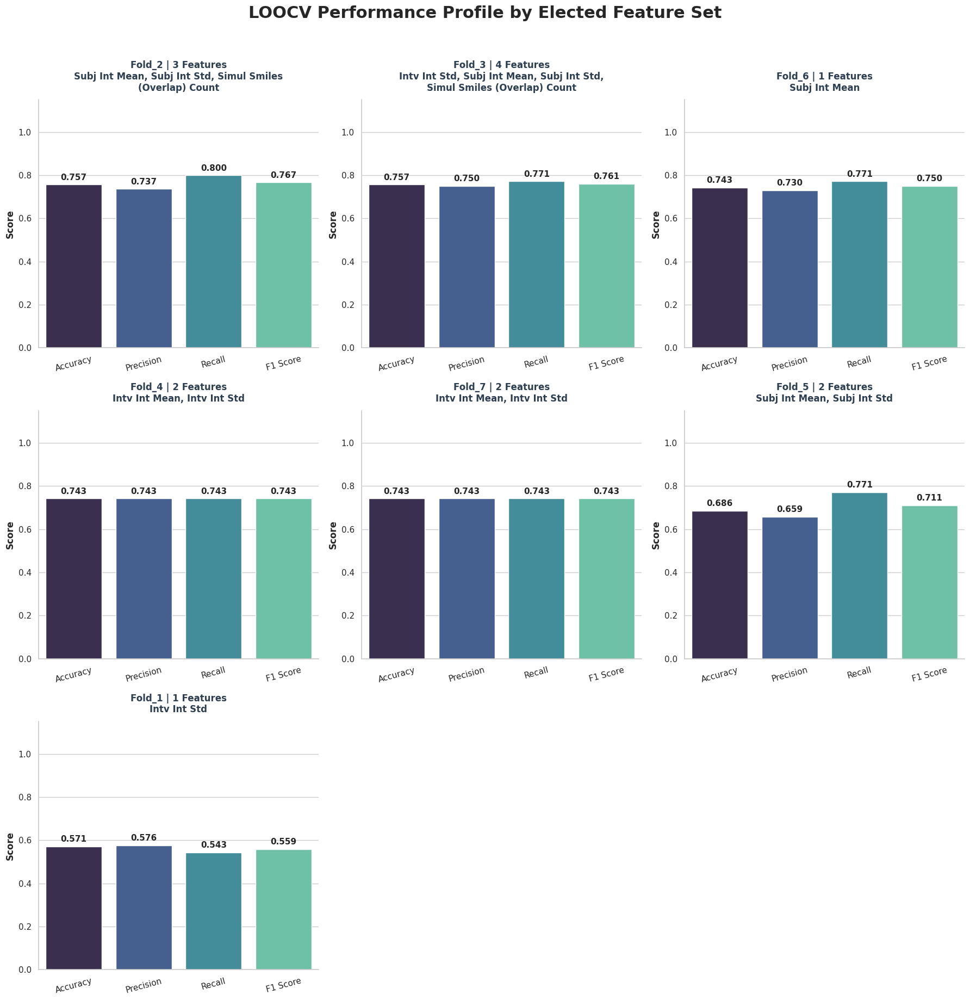

In [6]:
def evaluate_elected_features_loocv(X, y, elected_features_dict, random_state=42):
    """
    Evaluates each set of elected features using Leave-One-Out Cross-Validation (LOOCV).
    Plots a grid where each elected subset gets its own sub-figure showing all metrics.
    """
    total_samples = len(X)
    print(f"\n{'='*80}")
    print(f"EVALUATING FEATURE SETS USING LEAVE-ONE-OUT (Train: {total_samples - 1}, Test: 1)")
    print(f"{'='*80}\n")
    
    log_reg = LogisticRegression(C=np.inf, solver='saga', max_iter=10000, random_state=random_state)
    loo = LeaveOneOut()
    
    results = []
    
    for fold_name, features in elected_features_dict.items():
        X_subset = X[features]
        
        y_true_all = []
        y_pred_all = []
        
        # The LOOCV Loop
        for train_index, test_index in loo.split(X_subset):
            X_tr, X_te = X_subset.iloc[train_index], X_subset.iloc[test_index]
            y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
            
            log_reg.fit(X_tr, y_tr)
            pred = log_reg.predict(X_te)[0]
            
            y_true_all.append(y_te.values[0])
            y_pred_all.append(pred)
            
        acc = accuracy_score(y_true_all, y_pred_all)
        prec = precision_score(y_true_all, y_pred_all, zero_division=0)
        rec = recall_score(y_true_all, y_pred_all, zero_division=0)
        f1 = f1_score(y_true_all, y_pred_all, zero_division=0)
        
        # Abbreviate and wrap the feature names for plotting
        short_feats = [abbreviate_feature_name(f) for f in features]
        feat_string = ", ".join(short_feats)
        wrapped_labels = textwrap.fill(feat_string, width=45) # Wrapped for sub-figure titles
        
        results.append({
            'Source': fold_name,
            'Features_Display': wrapped_labels, 
            'Num_Features': len(features),
            'LOO_Accuracy': acc,
            'LOO_Precision': prec,
            'LOO_Recall': rec,
            'LOO_F1_Score': f1
        })
        
    results_df = pd.DataFrame(results)
    
    # Sort by Accuracy, then F1 so the best sets appear first in the grid
    results_df = results_df.sort_values(by=['LOO_Accuracy', 'LOO_F1_Score'], ascending=False).reset_index(drop=True)
    
    # Print tabular summary
    print(results_df[['Source', 'Num_Features', 'LOO_Accuracy', 'LOO_Precision', 'LOO_Recall', 'LOO_F1_Score']].to_string(index=False))
    
    # --- Visualization: Sub-figure per Elected Feature Set ---
    sns.set_theme(style="whitegrid", palette="muted")
    
    num_plots = len(results_df)
    cols = 3
    rows = int(np.ceil(num_plots / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 6 * rows))
    fig.suptitle('LOOCV Performance Profile by Elected Feature Set', fontsize=22, fontweight='bold', y=1.02)
    
    axes_flat = axes.flatten() if num_plots > 1 else [axes]
    
    # Iterate through the results and plot each as a separate bar chart
    for i, row in results_df.iterrows():
        ax = axes_flat[i]
        
        # Prepare the 4 metrics for this specific feature set
        plot_data = pd.DataFrame({
            'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
            'Score': [row['LOO_Accuracy'], row['LOO_Precision'], row['LOO_Recall'], row['LOO_F1_Score']]
        })
        
        # Plot
        sns.barplot(x='Metric', y='Score', data=plot_data, ax=ax, palette='mako')
        
        # Formatting
        ax.set_ylim(0, 1.15) # Leave room for the labels on top of the bars
        ax.set_ylabel('Score', fontsize=12, fontweight='bold')
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelsize=11, labelrotation=15)
        
        # Set a rich, descriptive title for the subplot
        title_text = f"{row['Source']} | {row['Num_Features']} Features\n{row['Features_Display']}"
        ax.set_title(title_text, fontsize=12, fontweight='bold', color='#2c3e50', pad=12)
        
        # Add numeric labels to bars
        for container in ax.containers:
            ax.bar_label(container, fmt='%.3f', padding=4, size=11, weight='bold')
            
    # Remove any empty subplots if the number of sets doesn't divide evenly by 3
    for j in range(i + 1, len(axes_flat)):
        fig.delaxes(axes_flat[j])

    sns.despine()
    plt.tight_layout()
    plt.show()
    
    return results_df

if __name__ == "__main__":
    DATA_PATH = '/home/amir/Ados_lab/final_feature_matrix.csv' 
    if os.path.exists(DATA_PATH): 
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        final_results_df = evaluate_elected_features_loocv(X=X_scaled, y=y, elected_features_dict=fold_best_features)

In [16]:
import itertools
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# =============================================================================
# 1. Load and Normalize Data
# =============================================================================
DATA_PATH = '/home/amir/Ados_lab/final_feature_matrix.csv' 
df_merged = pd.read_csv(DATA_PATH)

# Explicitly define your metadata so the script knows what NOT to plot
metadata_cols = ['Subject Number', 'Label', 'Gender']

# Automatically grab the remaining behavioral features
feature_cols = [col for col in df_merged.columns if col not in metadata_cols]


col_delay = "Average Delay of Reaction (s)"
col_std = "Std Dev of Delay of Reaction (s)"

if col_delay in df_merged.columns:
    df_merged[col_delay] = df_merged[col_delay].fillna(2.0)
    print(f"Applied 2.0s penalty to {col_delay}")

if col_std in df_merged.columns:
    df_merged[col_std] = df_merged[col_std].fillna(0.0)
    print(f"Applied 0.0 penalty to {col_std}")


# --- NORMALIZE THE FEATURES ---
# Standardize features to mean=0 and variance=1 so MSE is perfectly comparable across all plots
scaler = StandardScaler()
df_scaled = df_merged.copy()
df_scaled[feature_cols] = scaler.fit_transform(df_merged[feature_cols])

# Define where you want the 136 images to be saved
OUTPUT_DIR = '/home/amir/Ados_lab/videos2/results/pairwise_feature_plots'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Successfully loaded and normalized data for {len(df_scaled)} subjects.")
print(f"Detected {len(feature_cols)} behavioral features.")
print(f"Generating {len(feature_cols) * (len(feature_cols) - 1) // 2} unique pairwise plots...")

# =============================================================================
# 2. Memory-Safe Loop over all 136 Combinations
# =============================================================================
sns.set_theme(style="whitegrid", palette="muted")
label_palette = sns.color_palette("Set1", n_colors=df_scaled['Label'].nunique())

# Generate the unique pairs
pairwise_combinations = list(itertools.combinations(feature_cols, 2))

for idx, (x_feat, y_feat) in enumerate(pairwise_combinations, start=1):
    # Initialize figure
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # --- CALCULATE MSE FOR THE REGRESSION LINE ---
    # Isolate valid non-null rows specifically for this feature pair using the SCALED data
    valid_data = df_scaled[[x_feat, y_feat]].dropna()
    
    if len(valid_data) > 1:
        X_val = valid_data[[x_feat]].values
        y_val = valid_data[y_feat].values
        
        # Fit linear model to extract standard prediction residuals
        lr = LinearRegression()
        lr.fit(X_val, y_val)
        y_pred = lr.predict(X_val)
        
        mse = mean_squared_error(y_val, y_pred)
        line_label = f'(Normalized MSE: {mse:.4f})'
    else:
        line_label = '(Normalized MSE: N/A)'

    # --- PLOTTING ---
    # 1. Draw overall regression trendline in the background with the MSE label attached
    sns.regplot(
        data=df_scaled, 
        x=x_feat, 
        y=y_feat, 
        scatter=False, 
        ax=ax, 
        color='black', 
        line_kws={'linestyle': '--', 'alpha': 0.6},
        label=line_label  # <-- This adds the MSE metric to the legend
    )
    
    # 2. Overlay the hue-colored scatter points
    sns.scatterplot(
        data=df_scaled, 
        x=x_feat, 
        y=y_feat, 
        hue='Label', 
        palette=label_palette, 
        s=100, 
        alpha=0.8, 
        edgecolor='k', 
        ax=ax
    )
    
    # Format Titles and Labels
    ax.set_title(f'Plot {idx}/136: {x_feat} vs \n{y_feat}\n(Standardized)', fontsize=12, fontweight='bold')
    ax.set_xlabel(f"{x_feat} (Z-Score)", fontsize=10, fontweight='bold')
    ax.set_ylabel(f"{y_feat} (Z-Score)", fontsize=10, fontweight='bold')
    
    # Move the legend outside the plot area
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    
    sns.despine()
    plt.tight_layout()
    
    # Clean up the feature names so they are safe for Linux/Windows filenames
    def sanitize_filename(name):
        return name.replace(" ", "_").replace("(", "").replace(")", "").replace("->", "2").replace("%", "Pct").replace("/", "_")
    
    safe_x = sanitize_filename(x_feat)
    safe_y = sanitize_filename(y_feat)
    
    # Format: 001_FeatureX_vs_FeatureY.png
    filename = f"{idx:03d}_{safe_x}_vs_{safe_y}.png"
    filepath = os.path.join(OUTPUT_DIR, filename)
    
    # Save and instantly close the figure to prevent RAM memory leaks
    plt.savefig(filepath, dpi=150, bbox_inches='tight')
    plt.close(fig)

print(f"Finished! All 136 plots have been saved safely to: {OUTPUT_DIR}")

Applied 2.0s penalty to Average Delay of Reaction (s)
Applied 0.0 penalty to Std Dev of Delay of Reaction (s)
Successfully loaded and normalized data for 70 subjects.
Detected 17 behavioral features.
Generating 136 unique pairwise plots...
Finished! All 136 plots have been saved safely to: /home/amir/Ados_lab/videos2/results/pairwise_feature_plots


Applied 2.0s penalty to Average Delay of Reaction (s)
Applied 0.0 penalty to Std Dev of Delay of Reaction (s)
Loaded 70 subjects.
Generating Boxplot Dashboards for 17 features...


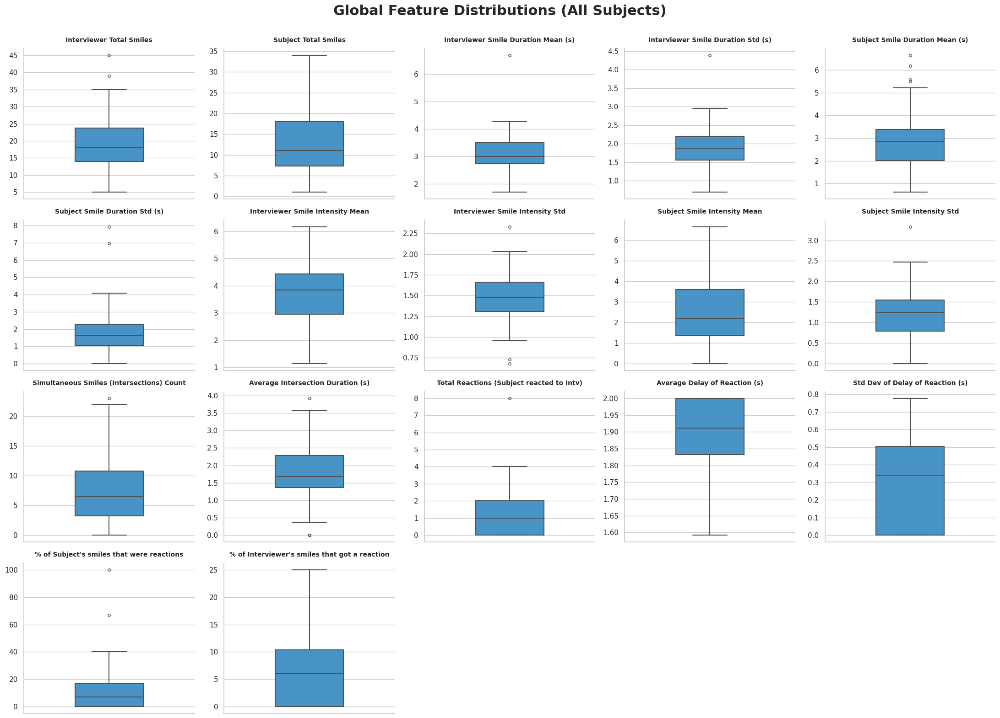

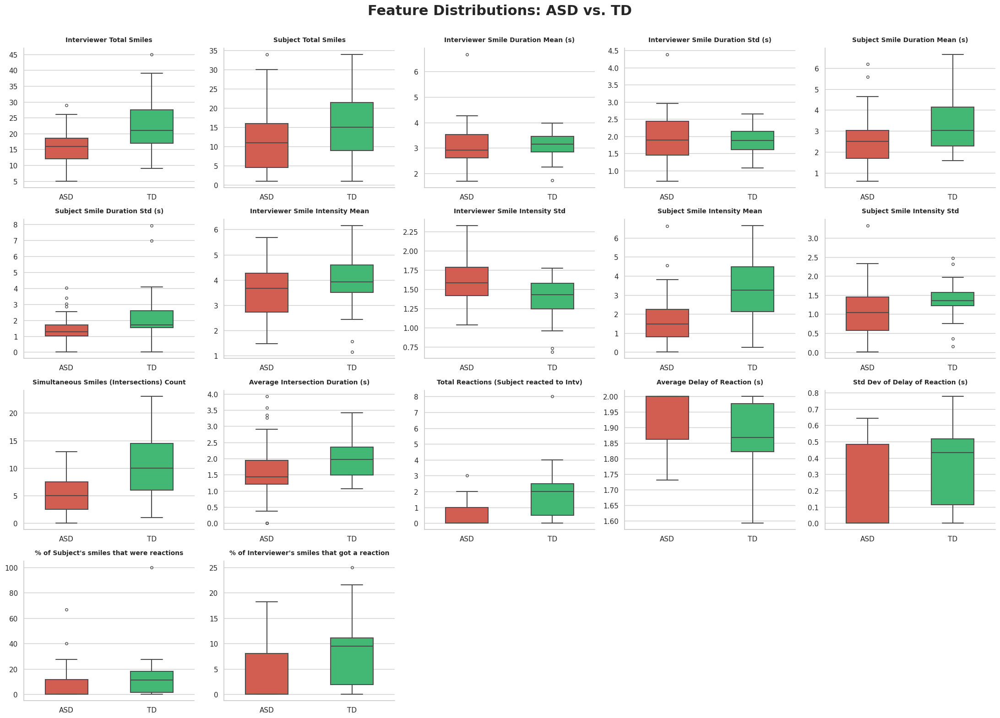

In [20]:
df = pd.read_csv(DATA_PATH)

# Explicitly define metadata so we only plot the behavioral features
metadata_cols = ['Subject Number', 'Label', 'Gender']
feature_cols = [col for col in df.columns if col not in metadata_cols]

col_delay = "Average Delay of Reaction (s)"
col_std = "Std Dev of Delay of Reaction (s)"

if col_delay in df_merged.columns:
    df_merged[col_delay] = df_merged[col_delay].fillna(2.0)
    print(f"Applied 2.0s penalty to {col_delay}")

if col_std in df_merged.columns:
    df_merged[col_std] = df_merged[col_std].fillna(0.0)
    print(f"Applied 0.0 penalty to {col_std}")


# Create a readable label column for the grouped plots (Optional, but looks cleaner)
df['Diagnosis'] = df['Label'].map({1: 'ASD', 0: 'TD'})

print(f"Loaded {len(df)} subjects.")
print(f"Generating Boxplot Dashboards for {len(feature_cols)} features...")

# =============================================================================
# 2. Figure 1: Overall Boxplots (Ignoring Labels)
# =============================================================================
sns.set_theme(style="whitegrid", palette="pastel")

# Create a 4x5 grid (20 slots for 17 features)
fig1, axes1 = plt.subplots(4, 5, figsize=(22, 16))
fig1.suptitle('Global Feature Distributions (All Subjects)', fontsize=22, fontweight='bold', y=0.98)

# Flatten the axes array for easy iteration
axes1_flat = axes1.flatten()

for i, feature in enumerate(feature_cols):
    ax = axes1_flat[i]
    # Vertical boxplot for the overall distribution
    sns.boxplot(y=df[feature], ax=ax, color='#3498db', width=0.4, linewidth=1.5, fliersize=4)
    
    # Format subplot
    ax.set_title(feature, fontsize=10, fontweight='bold', pad=10)
    ax.set_ylabel('') # Hide y-label to keep the grid clean
    
# Hide the remaining unused subplots (slots 17, 18, 19)
for j in range(i + 1, len(axes1_flat)):
    fig1.delaxes(axes1_flat[j])

sns.despine(fig=fig1)
fig1.tight_layout()
fig1.subplots_adjust(top=0.92)


# =============================================================================
# 3. Figure 2: Grouped Boxplots (ADOS vs. Non-ADOS)
# =============================================================================
# Set a distinct color palette for the two classes
class_palette = {'ASD': '#e74c3c', 'TD': '#2ecc71'}

fig2, axes2 = plt.subplots(4, 5, figsize=(22, 16))
fig2.suptitle('Feature Distributions: ASD vs. TD', fontsize=22, fontweight='bold', y=0.98)

axes2_flat = axes2.flatten()

for i, feature in enumerate(feature_cols):
    ax = axes2_flat[i]
    
    # Grouped boxplot comparing the two classes
    sns.boxplot(
        data=df, 
        x='Diagnosis', 
        y=feature, 
        hue='Diagnosis',
        palette=class_palette, 
        ax=ax, 
        width=0.5, 
        linewidth=1.5, 
        fliersize=4,
        legend=False # Hide legend per-subplot to avoid clutter
    )
    
    # Format subplot
    ax.set_title(feature, fontsize=10, fontweight='bold', pad=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    
# Hide the remaining unused subplots
for j in range(i + 1, len(axes2_flat)):
    fig2.delaxes(axes2_flat[j])

sns.despine(fig=fig2)
fig2.tight_layout()
fig2.subplots_adjust(top=0.92)

# =============================================================================
# 4. Display the Dashboards
# =============================================================================
plt.show()